Dataset shape: (5000, 2)

Label distribution:
Final_Label
0    2500
1    2500
Name: count, dtype: int64

Train: 3500
Validation: 750
Test: 750

VALIDATION RESULTS
               precision    recall  f1-score   support

Non-sarcastic       0.97      0.91      0.94       375
    Sarcastic       0.91      0.97      0.94       375

     accuracy                           0.94       750
    macro avg       0.94      0.94      0.94       750
 weighted avg       0.94      0.94      0.94       750

Metrics: {'Model': 'TF-IDF + Logistic Regression', 'Split': 'validation', 'Accuracy': 0.94, 'Precision_macro': 0.941661432160804, 'Recall_macro': 0.94, 'Macro_F1': 0.9399435202172355}

TEST RESULTS
               precision    recall  f1-score   support

Non-sarcastic       0.96      0.93      0.94       375
    Sarcastic       0.93      0.96      0.94       375

     accuracy                           0.94       750
    macro avg       0.94      0.94      0.94       750
 weighted avg       0.94     

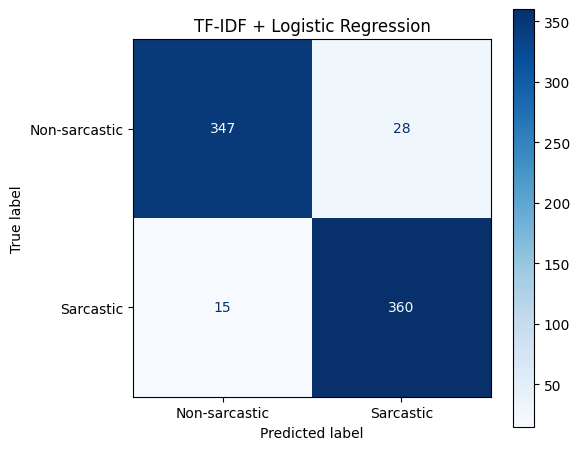


Model 1 complete.
Results saved to: /content/research_results/logistic_regression


In [ ]:

# ============================================================
# MODEL 1: TF-IDF + LOGISTIC REGRESSION
# Roman Urdu Sarcasm Detection Research
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. Configuration
DATA_PATH = "/content/roman_urdu_sarcasm_synthetic_5000.csv"
OUTPUT_DIR = "/content/research_results/logistic_regression"
RANDOM_STATE = 42

os.makedirs(OUTPUT_DIR, exist_ok=True)

# 2. Load dataset
df = pd.read_csv(DATA_PATH)

required_columns = ["Text", "Final_Label"]
missing = [c for c in required_columns if c not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

df = df[["Text", "Final_Label"]].dropna().copy()
df["Text"] = df["Text"].astype(str).str.strip()
df = df[df["Text"] != ""].copy()

# Ensure labels are binary 0 and 1
df["Final_Label"] = pd.to_numeric(
    df["Final_Label"], errors="raise"
).astype(int)

if not set(df["Final_Label"].unique()).issubset({0, 1}):
    raise ValueError("Final_Label must contain only 0 and 1.")

# Remove exact duplicate texts before splitting
df = df.drop_duplicates(subset=["Text"]).reset_index(drop=True)

X = df["Text"]
y = df["Final_Label"]

print("Dataset shape:", df.shape)
print("\nLabel distribution:")
print(y.value_counts().sort_index())

# 3. Split dataset
# IMPORTANT:

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

# Save split assignments for reproducibility
split_df = pd.DataFrame({
    "Text": pd.concat([X_train, X_val, X_test]),
    "Label": pd.concat([y_train, y_val, y_test]),
    "Split": (
        ["train"] * len(X_train)
        + ["validation"] * len(X_val)
        + ["test"] * len(X_test)
    )
})

split_df.to_csv(
    os.path.join(OUTPUT_DIR, "split_assignments.csv"),
    index=False
)

print(f"\nTrain: {len(X_train)}")
print(f"Validation: {len(X_val)}")
print(f"Test: {len(X_test)}")

# 4. Build model
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="word",
        ngram_range=(1, 2),
        min_df=2,
        max_features=30000,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

# 5. Train
model.fit(X_train, y_train)

# 6. Evaluate on validation and test sets
def evaluate_model(model, X_eval, y_eval, split_name):
    predictions = model.predict(X_eval)

    metrics = {
        "Model": "TF-IDF + Logistic Regression",
        "Split": split_name,
        "Accuracy": accuracy_score(y_eval, predictions),
        "Precision_macro": precision_score(
            y_eval, predictions, average="macro", zero_division=0
        ),
        "Recall_macro": recall_score(
            y_eval, predictions, average="macro", zero_division=0
        ),
        "Macro_F1": f1_score(
            y_eval, predictions, average="macro", zero_division=0
        )
    }

    print(f"\n{split_name.upper()} RESULTS")
    print(classification_report(
        y_eval,
        predictions,
        labels=[0, 1],
        target_names=["Non-sarcastic", "Sarcastic"],
        zero_division=0
    ))
    print("Metrics:", metrics)

    return metrics, predictions

val_metrics, val_predictions = evaluate_model(
    model, X_val, y_val, "validation"
)

test_metrics, test_predictions = evaluate_model(
    model, X_test, y_test, "test"
)

# 7. Save metrics and predictions
pd.DataFrame([val_metrics, test_metrics]).to_csv(
    os.path.join(OUTPUT_DIR, "metrics.csv"),
    index=False
)

pd.DataFrame({
    "Text": X_test.values,
    "True_Label": y_test.values,
    "Predicted_Label": test_predictions
}).to_csv(
    os.path.join(OUTPUT_DIR, "test_predictions.csv"),
    index=False
)

# 8. Publication-quality confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=[0, 1],
    display_labels=["Non-sarcastic", "Sarcastic"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("TF-IDF + Logistic Regression")
fig.tight_layout()

fig.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)
fig.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix.pdf"),
    bbox_inches="tight"
)
plt.show()

# 9. Save model
joblib.dump(
    model,
    os.path.join(OUTPUT_DIR, "logistic_regression_model.joblib")
)

print("\nModel 1 complete.")
print("Results saved to:", OUTPUT_DIR)


Dataset shape: (5000, 2)

Label distribution:
Final_Label
0    2500
1    2500
Name: count, dtype: int64

Train: 3500
Validation: 750
Test: 750

VALIDATION RESULTS
               precision    recall  f1-score   support

Non-sarcastic       0.98      0.95      0.97       375
    Sarcastic       0.95      0.98      0.97       375

     accuracy                           0.97       750
    macro avg       0.97      0.97      0.97       750
 weighted avg       0.97      0.97      0.97       750

Metrics: {'Model': 'TF-IDF + Linear SVM', 'Split': 'validation', 'Accuracy': 0.968, 'Precision_macro': 0.9684797232365943, 'Recall_macro': 0.968, 'Macro_F1': 0.9679918059023109}

TEST RESULTS
               precision    recall  f1-score   support

Non-sarcastic       0.98      0.96      0.97       375
    Sarcastic       0.96      0.98      0.97       375

     accuracy                           0.97       750
    macro avg       0.97      0.97      0.97       750
 weighted avg       0.97      0.97 

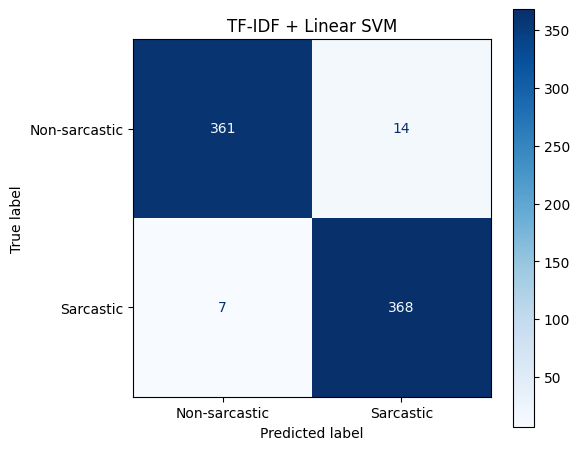


Model 2 complete.
Results saved to: /content/research_results/linear_svm


In [ ]:

# ============================================================
# MODEL 2: TF-IDF + LINEAR SVM
# Roman Urdu Sarcasm Detection Research
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. Configuration
DATA_PATH = "/content/roman_urdu_sarcasm_synthetic_5000.csv"
OUTPUT_DIR = "/content/research_results/linear_svm"
RANDOM_STATE = 42

os.makedirs(OUTPUT_DIR, exist_ok=True)

# 2. Load and validate dataset
df = pd.read_csv(DATA_PATH)

required_columns = ["Text", "Final_Label"]
missing = [c for c in required_columns if c not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

df = df[["Text", "Final_Label"]].dropna().copy()
df["Text"] = df["Text"].astype(str).str.strip()
df = df[df["Text"] != ""].copy()

df["Final_Label"] = pd.to_numeric(
    df["Final_Label"], errors="raise"
).astype(int)

if not set(df["Final_Label"].unique()).issubset({0, 1}):
    raise ValueError("Final_Label must contain only 0 and 1.")

df = df.drop_duplicates(subset=["Text"]).reset_index(drop=True)

X = df["Text"]
y = df["Final_Label"]

print("Dataset shape:", df.shape)
print("\nLabel distribution:")
print(y.value_counts().sort_index())

# 3. Split dataset

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

split_df = pd.DataFrame({
    "Text": pd.concat([X_train, X_val, X_test]),
    "Label": pd.concat([y_train, y_val, y_test]),
    "Split": (
        ["train"] * len(X_train)
        + ["validation"] * len(X_val)
        + ["test"] * len(X_test)
    )
})

split_df.to_csv(
    os.path.join(OUTPUT_DIR, "split_assignments.csv"),
    index=False
)

print(f"\nTrain: {len(X_train)}")
print(f"Validation: {len(X_val)}")
print(f"Test: {len(X_test)}")

# 4. Build model
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="word",
        ngram_range=(1, 2),
        min_df=2,
        max_features=30000,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        C=1.0,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        max_iter=5000
    ))
])

# 5. Train
model.fit(X_train, y_train)

# 6. Evaluate
def evaluate_model(model, X_eval, y_eval, split_name):
    predictions = model.predict(X_eval)

    metrics = {
        "Model": "TF-IDF + Linear SVM",
        "Split": split_name,
        "Accuracy": accuracy_score(y_eval, predictions),
        "Precision_macro": precision_score(
            y_eval, predictions, average="macro", zero_division=0
        ),
        "Recall_macro": recall_score(
            y_eval, predictions, average="macro", zero_division=0
        ),
        "Macro_F1": f1_score(
            y_eval, predictions, average="macro", zero_division=0
        )
    }

    print(f"\n{split_name.upper()} RESULTS")
    print(classification_report(
        y_eval,
        predictions,
        labels=[0, 1],
        target_names=["Non-sarcastic", "Sarcastic"],
        zero_division=0
    ))
    print("Metrics:", metrics)

    return metrics, predictions

val_metrics, val_predictions = evaluate_model(
    model, X_val, y_val, "validation"
)

test_metrics, test_predictions = evaluate_model(
    model, X_test, y_test, "test"
)

# 7. Save metrics and predictions
pd.DataFrame([val_metrics, test_metrics]).to_csv(
    os.path.join(OUTPUT_DIR, "metrics.csv"),
    index=False
)

pd.DataFrame({
    "Text": X_test.values,
    "True_Label": y_test.values,
    "Predicted_Label": test_predictions
}).to_csv(
    os.path.join(OUTPUT_DIR, "test_predictions.csv"),
    index=False
)

# 8. Publication-quality confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=[0, 1],
    display_labels=["Non-sarcastic", "Sarcastic"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("TF-IDF + Linear SVM")
fig.tight_layout()

fig.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)
fig.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix.pdf"),
    bbox_inches="tight"
)
plt.show()

# 9. Save trained model
joblib.dump(
    model,
    os.path.join(OUTPUT_DIR, "linear_svm_model.joblib")
)

print("\nModel 2 complete.")
print("Results saved to:", OUTPUT_DIR)


Dataset shape: (5000, 2)

Label distribution:
Final_Label
0    2500
1    2500
Name: count, dtype: int64

Training examples: 3500
Validation examples: 750
Test examples: 750

Training Character n-gram TF-IDF + Linear SVM...

VALIDATION RESULTS
               precision    recall  f1-score   support

Non-sarcastic       0.99      0.96      0.98       375
    Sarcastic       0.96      0.99      0.98       375

     accuracy                           0.98       750
    macro avg       0.98      0.98      0.98       750
 weighted avg       0.98      0.98      0.98       750

Metrics: {'Model': 'Character n-gram TF-IDF + Linear SVM', 'Split': 'validation', 'Accuracy': 0.976, 'Precision_macro': 0.9764879236338011, 'Recall_macro': 0.976, 'Macro_F1': 0.9759938544267333}

TEST RESULTS
               precision    recall  f1-score   support

Non-sarcastic       0.99      0.98      0.98       375
    Sarcastic       0.98      0.99      0.98       375

     accuracy                           0.98    

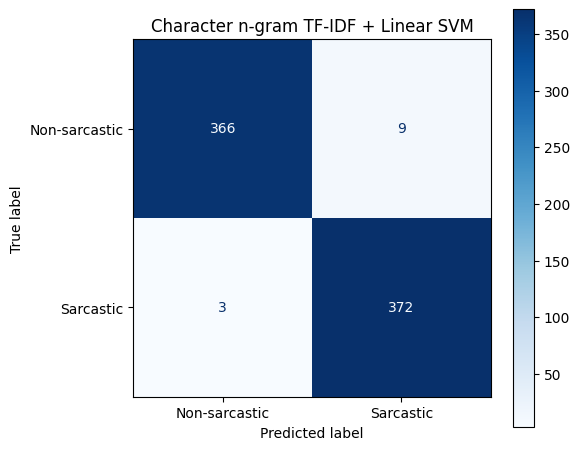


Model 3 completed successfully.
All results saved to: /content/research_results/char_ngram_svm

Saved files:
- char_ngram_svm_model.joblib
- confusion_matrix.pdf
- confusion_matrix.png
- metrics.csv
- split_assignments.csv
- test_predictions.csv


In [ ]:

# ============================================================
# MODEL 3: CHARACTER N-GRAM TF-IDF + LINEAR SVM
# Roman Urdu Sarcasm Detection Research
# ============================================================

import os
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. Configuration
DATA_PATH = "/content/roman_urdu_sarcasm_synthetic_5000.csv"
OUTPUT_DIR = "/content/research_results/char_ngram_svm"
RANDOM_STATE = 42

os.makedirs(OUTPUT_DIR, exist_ok=True)

# 2. Load dataset
df = pd.read_csv(DATA_PATH)

required_columns = ["Text", "Final_Label"]
missing = [c for c in required_columns if c not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

df = df[["Text", "Final_Label"]].dropna().copy()
df["Text"] = df["Text"].astype(str).str.strip()
df = df[df["Text"] != ""].copy()

df["Final_Label"] = pd.to_numeric(
    df["Final_Label"], errors="raise"
).astype(int)

if not set(df["Final_Label"].unique()).issubset({0, 1}):
    raise ValueError("Final_Label must contain only 0 and 1.")

# Remove exact duplicate text
df = df.drop_duplicates(subset=["Text"]).reset_index(drop=True)

X = df["Text"]
y = df["Final_Label"]

print("Dataset shape:", df.shape)
print("\nLabel distribution:")
print(y.value_counts().sort_index())

# 3. Split dataset

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

# Save split assignments
split_df = pd.DataFrame({
    "Text": pd.concat([X_train, X_val, X_test]),
    "Label": pd.concat([y_train, y_val, y_test]),
    "Split": (
        ["train"] * len(X_train)
        + ["validation"] * len(X_val)
        + ["test"] * len(X_test)
    )
})

split_df.to_csv(
    os.path.join(OUTPUT_DIR, "split_assignments.csv"),
    index=False
)

print(f"\nTraining examples: {len(X_train)}")
print(f"Validation examples: {len(X_val)}")
print(f"Test examples: {len(X_test)}")

# 4. Build character n-gram model
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=(2, 5),
        min_df=2,
        max_features=50000,
        sublinear_tf=True,
        lowercase=True
    )),
    ("classifier", LinearSVC(
        C=1.0,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        max_iter=5000
    ))
])

# 5. Train
print("\nTraining Character n-gram TF-IDF + Linear SVM...")
model.fit(X_train, y_train)

# 6. Evaluation function
def evaluate_model(model, X_eval, y_eval, split_name):
    predictions = model.predict(X_eval)

    metrics = {
        "Model": "Character n-gram TF-IDF + Linear SVM",
        "Split": split_name,
        "Accuracy": accuracy_score(y_eval, predictions),
        "Precision_macro": precision_score(
            y_eval, predictions,
            average="macro", zero_division=0
        ),
        "Recall_macro": recall_score(
            y_eval, predictions,
            average="macro", zero_division=0
        ),
        "Macro_F1": f1_score(
            y_eval, predictions,
            average="macro", zero_division=0
        )
    }

    print(f"\n{split_name.upper()} RESULTS")

    print(classification_report(
        y_eval,
        predictions,
        labels=[0, 1],
        target_names=["Non-sarcastic", "Sarcastic"],
        zero_division=0
    ))

    print("Metrics:", metrics)

    return metrics, predictions

# Evaluate validation and test sets
val_metrics, val_predictions = evaluate_model(
    model, X_val, y_val, "validation"
)

test_metrics, test_predictions = evaluate_model(
    model, X_test, y_test, "test"
)

# 7. Save metrics
pd.DataFrame([val_metrics, test_metrics]).to_csv(
    os.path.join(OUTPUT_DIR, "metrics.csv"),
    index=False
)

# 8. Save test predictions
pd.DataFrame({
    "Text": X_test.values,
    "True_Label": y_test.values,
    "Predicted_Label": test_predictions
}).to_csv(
    os.path.join(OUTPUT_DIR, "test_predictions.csv"),
    index=False
)

# 9. Save confusion matrix: PNG and PDF
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=[0, 1],
    display_labels=["Non-sarcastic", "Sarcastic"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("Character n-gram TF-IDF + Linear SVM")
fig.tight_layout()

fig.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix.pdf"),
    bbox_inches="tight"
)

plt.show()

# 10. Save trained model
joblib.dump(
    model,
    os.path.join(OUTPUT_DIR, "char_ngram_svm_model.joblib")
)

print("\nModel 3 completed successfully.")
print("All results saved to:", OUTPUT_DIR)
print("\nSaved files:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print("-", filename)


Dataset size: 5000
labels
0    2500
1    2500
Name: count, dtype: int64
Train: 3500, Validation: 750, Test: 750


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/3500 [00:00<?, ? examples/s]

Map:   0%|          | 0/750 [00:00<?, ? examples/s]

Map:   0%|          | 0/750 [00:00<?, ? examples/s]

... (11 outputs left out)

Training Loss,Validation Loss,Epoch,Accuracy,Macro Precision,Macro Recall,Macro F1
0.518420,0.492142,3,0.785333,0.798585,0.785333,0.782925



Validation results:
{'eval_loss': 0.513852059841156, 'eval_accuracy': 0.768, 'eval_macro_precision': 0.7741128381179585, 'eval_macro_recall': 0.768, 'eval_macro_f1': 0.7666993228023256}

Test results:
{'test_loss': 0.49214208126068115, 'test_accuracy': 0.7853333333333333, 'test_macro_precision': 0.7985846529348732, 'test_macro_recall': 0.7853333333333334, 'test_macro_f1': 0.7829248605415822}


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



Test classification report:
               precision    recall  f1-score   support

Non-sarcastic       0.86      0.68      0.76       375
    Sarcastic       0.74      0.89      0.81       375

     accuracy                           0.79       750
    macro avg       0.80      0.79      0.78       750
 weighted avg       0.80      0.79      0.78       750



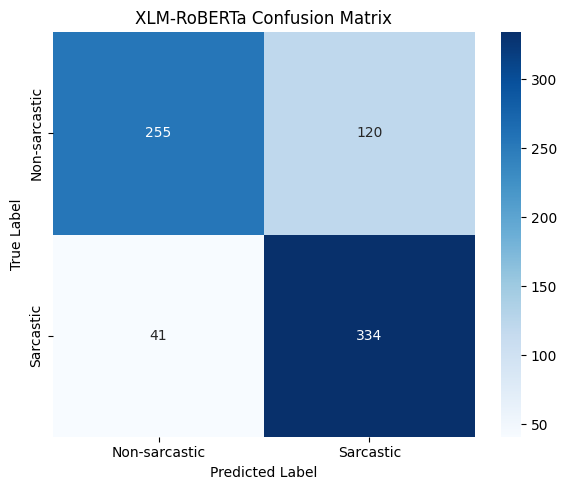

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Saved outputs to: /content/research_results/xlmr


In [ ]:

# Install dependencies
!pip -q install transformers datasets accelerate scikit-learn pandas matplotlib seaborn

# Imports
import os
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Dataset path
DATA_PATH = "/content/roman_urdu_sarcasm_synthetic_5000.csv"

# Output directory
OUT_DIR = "/content/research_results/xlmr"
os.makedirs(OUT_DIR, exist_ok=True)

# Load dataset
df = pd.read_csv(DATA_PATH)

required_columns = ["Text", "Final_Label"]
missing = [c for c in required_columns if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

df = df[["Text", "Final_Label"]].dropna().copy()
df["Text"] = df["Text"].astype(str).str.strip()
df = df[df["Text"] != ""]
df = df.drop_duplicates(subset=["Text"]).reset_index(drop=True)

# Normalize labels to 0/1
df["Final_Label"] = pd.to_numeric(df["Final_Label"], errors="raise").astype(int)
if not set(df["Final_Label"].unique()).issubset({0, 1}):
    raise ValueError("Final_Label must contain only 0 and 1.")

df = df.rename(columns={"Final_Label": "labels"})

print("Dataset size:", len(df))
print(df["labels"].value_counts())

# PROVISIONAL random stratified split.
# We will replace this with a shared template-grouped split
# for the final comparison across all four models.
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["labels"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["labels"],
    random_state=SEED
)

print(f"Train: {len(train_df)}, Validation: {len(val_df)}, Test: {len(test_df)}")

# Load multilingual XLM-RoBERTa
MODEL_NAME = "xlm-roberta-base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

# Tokenization
MAX_LENGTH = 128

def tokenize_batch(batch):
    return tokenizer(
        batch["Text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

def to_hf_dataset(frame):
    dataset = Dataset.from_pandas(
        frame[["Text", "labels"]].reset_index(drop=True),
        preserve_index=False
    )
    return dataset.map(tokenize_batch, batched=True)

train_ds = to_hf_dataset(train_df)
val_ds = to_hf_dataset(val_df)
test_ds = to_hf_dataset(test_df)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Metrics
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    precision, recall, macro_f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    accuracy = accuracy_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": macro_f1
    }

# Training configuration
training_args = TrainingArguments(
    output_dir=f"{OUT_DIR}/checkpoints",
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="eval_macro_f1",
    greater_is_better=True,
    save_total_limit=2,
    seed=SEED,
    data_seed=SEED,
    fp16=torch.cuda.is_available(),
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

# Train
trainer.train()

# Evaluate on validation and test sets
val_results = trainer.evaluate(val_ds)
test_results = trainer.evaluate(test_ds, metric_key_prefix="test")

print("\nValidation results:")
print(val_results)

print("\nTest results:")
print(test_results)

# Test predictions
prediction_output = trainer.predict(test_ds)
y_true = prediction_output.label_ids
y_pred = np.argmax(prediction_output.predictions, axis=-1)

print("\nTest classification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Non-sarcastic", "Sarcastic"],
    zero_division=0
))

# Save metrics
metrics = {
    "model": "XLM-RoBERTa-base",
    "seed": SEED,
    "max_length": MAX_LENGTH,
    "epochs": 3,
    "train_size": len(train_df),
    "validation_size": len(val_df),
    "test_size": len(test_df),
    "test_accuracy": accuracy_score(y_true, y_pred)
}

precision, recall, f1, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

metrics["test_macro_precision"] = precision
metrics["test_macro_recall"] = recall
metrics["test_macro_f1"] = f1

pd.DataFrame([metrics]).to_csv(
    f"{OUT_DIR}/metrics.csv",
    index=False
)

# Save predictions
pd.DataFrame({
    "Text": test_df["Text"].reset_index(drop=True),
    "True_Label": y_true,
    "Predicted_Label": y_pred
}).to_csv(
    f"{OUT_DIR}/test_predictions.csv",
    index=False
)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-sarcastic", "Sarcastic"],
    yticklabels=["Non-sarcastic", "Sarcastic"]
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("XLM-RoBERTa Confusion Matrix")
plt.tight_layout()

plt.savefig(f"{OUT_DIR}/confusion_matrix.png", dpi=300)
plt.savefig(f"{OUT_DIR}/confusion_matrix.pdf")
plt.show()

# Save fine-tuned model and tokenizer
trainer.save_model(f"{OUT_DIR}/best_model")
tokenizer.save_pretrained(f"{OUT_DIR}/best_model")

print(f"\nSaved outputs to: {OUT_DIR}")


In [ ]:

# ============================================================
# SHARED TEMPLATE-GROUPED SPLIT FOR ALL FOUR MODELS
# ============================================================

!pip -q install scikit-learn pandas numpy

import os
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit

# -------------------------
# Configuration
# -------------------------
DATA_PATH = "/content/roman_urdu_sarcasm_synthetic_5000.csv"
SPLIT_DIR = "/content/research_results/shared_split"

SEED = 42
N_TRIALS = 1000

os.makedirs(SPLIT_DIR, exist_ok=True)

# -------------------------
# Load and validate dataset
# -------------------------
df = pd.read_csv(DATA_PATH)

required = ["Text", "Final_Label", "Template_ID"]
missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(
        f"Missing columns: {missing}. "
        "Template_ID is required for template-grouped splitting."
    )

df = df.dropna(subset=required).copy()
df["Text"] = df["Text"].astype(str).str.strip()
df["Template_ID"] = df["Template_ID"].astype(str).str.strip()
df["Final_Label"] = pd.to_numeric(
    df["Final_Label"], errors="raise"
).astype(int)

df = df[
    (df["Text"] != "") &
    (df["Template_ID"] != "")
].copy()

if not set(df["Final_Label"].unique()).issubset({0, 1}):
    raise ValueError("Final_Label must contain only 0 and 1.")


df = df.drop_duplicates(subset=["Text"]).reset_index(drop=True)

# Stable ID for auditing each row's assignment
df.insert(0, "Row_ID", np.arange(len(df)))

print("Rows after cleaning:", len(df))
print("\nLabel distribution:")
print(df["Final_Label"].value_counts().sort_index())

print("\nUnique templates:", df["Template_ID"].nunique())


labels_per_template = df.groupby("Template_ID")["Final_Label"].nunique()
mixed_templates = labels_per_template[labels_per_template > 1]

if len(mixed_templates) > 0:
    print(
        f"\nWARNING: {len(mixed_templates)} templates contain "
        "both labels. This may be legitimate, but inspect these "
        "templates and their labeling before final evaluation."
    )

# -------------------------
def best_group_split(frame, group_col, test_size, seed, trials=1000):
    """
    Returns row indices for a group-disjoint split.
    Selects the candidate closest to the requested row size
    and original label proportions.
    """
    y = frame["Final_Label"].to_numpy()
    groups = frame[group_col].to_numpy()

    overall_props = (
        frame["Final_Label"]
        .value_counts(normalize=True)
        .reindex([0, 1], fill_value=0)
        .to_numpy()
    )

    best = None
    best_score = float("inf")

    for i in range(trials):
        splitter = GroupShuffleSplit(
            n_splits=1,
            test_size=test_size,
            random_state=seed + i
        )

        train_idx, held_idx = next(
            splitter.split(frame, y, groups)
        )

        train_frame = frame.iloc[train_idx]
        held_frame = frame.iloc[held_idx]

        # Require both labels in both portions
        if train_frame["Final_Label"].nunique() < 2:
            continue
        if held_frame["Final_Label"].nunique() < 2:
            continue

        train_props = (
            train_frame["Final_Label"]
            .value_counts(normalize=True)
            .reindex([0, 1], fill_value=0)
            .to_numpy()
        )
        held_props = (
            held_frame["Final_Label"]
            .value_counts(normalize=True)
            .reindex([0, 1], fill_value=0)
            .to_numpy()
        )

        size_error = abs(len(held_idx) / len(frame) - test_size)
        balance_error = (
            np.abs(train_props - overall_props).sum()
            + np.abs(held_props - overall_props).sum()
        )

        score = size_error + balance_error

        if score < best_score:
            best_score = score
            best = (train_idx, held_idx)

    if best is None:
        raise ValueError(
            "Could not find a group-safe split containing both labels. "
            "Inspect template sizes and label distribution."
        )

    return best

# -------------------------
# Split 1: 70% train, 30% temporary
# -------------------------
train_idx, temp_idx = best_group_split(
    df,
    group_col="Template_ID",
    test_size=0.30,
    seed=SEED,
    trials=N_TRIALS
)

train_df = df.iloc[train_idx].copy().reset_index(drop=True)
temp_df = df.iloc[temp_idx].copy().reset_index(drop=True)

# -------------------------
# Split 2: temporary into
# approximately 15% validation
# and 15% test overall
# -------------------------
val_idx, test_idx = best_group_split(
    temp_df,
    group_col="Template_ID",
    test_size=0.50,
    seed=SEED + 10000,
    trials=N_TRIALS
)

val_df = temp_df.iloc[val_idx].copy().reset_index(drop=True)
test_df = temp_df.iloc[test_idx].copy().reset_index(drop=True)

# -------------------------
# Verify no template overlap
# -------------------------
train_groups = set(train_df["Template_ID"])
val_groups = set(val_df["Template_ID"])
test_groups = set(test_df["Template_ID"])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

# Verify no exact text overlap
assert set(train_df["Text"]).isdisjoint(set(val_df["Text"]))
assert set(train_df["Text"]).isdisjoint(set(test_df["Text"]))
assert set(val_df["Text"]).isdisjoint(set(test_df["Text"]))

# -------------------------
# Save the exact shared split
# -------------------------
train_df.to_csv(f"{SPLIT_DIR}/train.csv", index=False)
val_df.to_csv(f"{SPLIT_DIR}/validation.csv", index=False)
test_df.to_csv(f"{SPLIT_DIR}/test.csv", index=False)

assignments = pd.concat([
    train_df[["Row_ID", "Text", "Final_Label", "Template_ID"]]
        .assign(Split="train"),
    val_df[["Row_ID", "Text", "Final_Label", "Template_ID"]]
        .assign(Split="validation"),
    test_df[["Row_ID", "Text", "Final_Label", "Template_ID"]]
        .assign(Split="test")
], ignore_index=True)

assignments.to_csv(
    f"{SPLIT_DIR}/split_assignments.csv",
    index=False
)

# -------------------------
# Report split statistics
# -------------------------
for name, part in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}")
    print("Rows:", len(part))
    print("Percentage:", round(100 * len(part) / len(df), 2), "%")
    print("Unique templates:", part["Template_ID"].nunique())
    print("Label counts:")
    print(part["Final_Label"].value_counts().sort_index())

print("\nShared split saved to:", SPLIT_DIR)
print("Files: train.csv, validation.csv, test.csv, split_assignments.csv")
print("Template overlap checks passed.")


Rows after cleaning: 5000

Label distribution:
Final_Label
0    2500
1    2500
Name: count, dtype: int64

Unique templates: 104

Train
Rows: 3484
Percentage: 69.68 %
Unique templates: 72
Label counts:
Final_Label
0    1743
1    1741
Name: count, dtype: int64

Validation
Rows: 754
Percentage: 15.08 %
Unique templates: 16
Label counts:
Final_Label
0    375
1    379
Name: count, dtype: int64

Test
Rows: 762
Percentage: 15.24 %
Unique templates: 16
Label counts:
Final_Label
0    382
1    380
Name: count, dtype: int64

Shared split saved to: /content/research_results/shared_split
Files: train.csv, validation.csv, test.csv, split_assignments.csv
Template overlap checks passed.


In [ ]:

import re
import pandas as pd
from pathlib import Path

SPLIT_DIR = Path("/content/research_results/shared_split")

splits = {
    "train": pd.read_csv(SPLIT_DIR / "train.csv"),
    "validation": pd.read_csv(SPLIT_DIR / "validation.csv"),
    "test": pd.read_csv(SPLIT_DIR / "test.csv"),
}

def normalize_text(value):
    if pd.isna(value):
        return ""
    value = str(value).lower().strip()
    return re.sub(r"\s+", " ", value)

# Basic integrity checks
for name, df in splits.items():
    print(f"\n{name.upper()}: {len(df)} rows")
    print("Columns:", len(df.columns))

    if "Row_ID" in df.columns:
        assert df["Row_ID"].notna().all(), f"{name}: missing Row_ID"
        assert df["Row_ID"].is_unique, f"{name}: duplicate Row_ID"

    assert df["Text"].notna().all(), f"{name}: missing Text"
    assert df["Final_Label"].notna().all(), f"{name}: missing labels"
    assert set(df["Final_Label"].unique()).issubset({0, 1})

# Check overlap in potentially important grouping fields.
fields_to_check = [
    "Row_ID",
    "Template_ID",
    "Group_ID",
    "Source_Group",
    "Canonical_Text",
    "Text",
]

for field in fields_to_check:
    if not all(field in df.columns for df in splits.values()):
        print(f"\nSKIPPED {field}: not present in every split.")
        continue

    sets = {}
    for name, df in splits.items():
        values = df[field].dropna()

        if field in {"Text", "Canonical_Text"}:
            values = values.map(normalize_text)

        values = values.astype(str).str.strip()
        sets[name] = set(values) - {""}

    print(f"\nOverlap audit: {field}")
    for a, b in [
        ("train", "validation"),
        ("train", "test"),
        ("validation", "test"),
    ]:
        overlap = sets[a] & sets[b]
        print(f"{a} vs {b}: {len(overlap)} shared values")

        if overlap:
            print("Examples:", list(sorted(overlap))[:5])


combined = pd.concat(
    [df.assign(_split=name) for name, df in splits.items()],
    ignore_index=True
)

if "Row_ID" in combined.columns:
    assert not combined["Row_ID"].duplicated().any(), (
        "A Row_ID appears in multiple splits."
    )

print("\nAudit completed. Review every nonzero overlap.")



TRAIN: 3484 rows
Columns: 20

VALIDATION: 754 rows
Columns: 20

TEST: 762 rows
Columns: 20

Overlap audit: Row_ID
train vs validation: 0 shared values
train vs test: 0 shared values
validation vs test: 0 shared values

Overlap audit: Template_ID
train vs validation: 0 shared values
train vs test: 0 shared values
validation vs test: 0 shared values

Overlap audit: Group_ID
train vs validation: 408 shared values
Examples: ['COM-BN00', 'COM-BN01', 'COM-BN02', 'COM-BN03', 'COM-BN04']
train vs test: 451 shared values
Examples: ['COM-BN00', 'COM-BN03', 'COM-GN00', 'COM-GN01', 'COM-GN02']
validation vs test: 222 shared values
Examples: ['COM-BN00', 'COM-BN03', 'COM-GN00', 'COM-GN01', 'COM-GN02']

Overlap audit: Source_Group
train vs validation: 16 shared values
Examples: ['synthetic:Comedy', 'synthetic:Cricket', 'synthetic:Economy', 'synthetic:Education', 'synthetic:Entertainment']
train vs test: 16 shared values
Examples: ['synthetic:Comedy', 'synthetic:Cricket', 'synthetic:Economy', 'synth

model 1

Template_ID disjointness: PASSED
Train: 3484
Validation: 754
Test: 762

Training labels:
Final_Label
0    1743
1    1741
Name: count, dtype: int64

Model trained on the shared grouped training split.

VALIDATION RESULTS
               precision    recall  f1-score   support

Non-sarcastic       0.58      0.63      0.60       375
    Sarcastic       0.60      0.55      0.57       379

     accuracy                           0.59       754
    macro avg       0.59      0.59      0.59       754
 weighted avg       0.59      0.59      0.59       754

Metrics: {'Model': 'TF-IDF + Logistic Regression', 'Split': 'validation', 'Accuracy': 0.5875331564986738, 'Precision_macro': 0.5883486342513884, 'Recall_macro': 0.5877537379067722, 'Macro_F1': 0.5869220945083014}

TEST RESULTS
               precision    recall  f1-score   support

Non-sarcastic       0.68      0.88      0.77       382
    Sarcastic       0.83      0.58      0.68       380

     accuracy                           0.73       76

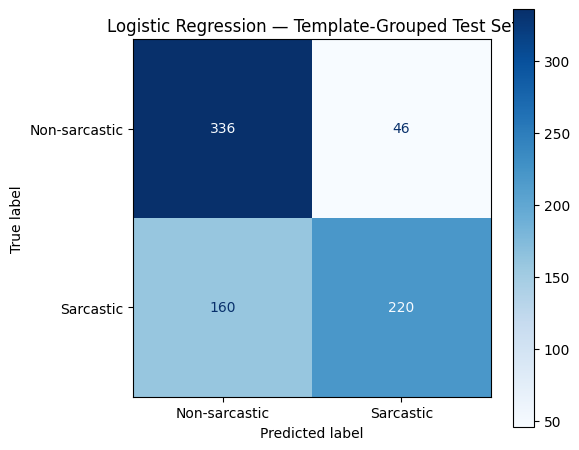

Model 1 artifacts saved to: /content/research_results/grouped_split/logistic_regression
Files:
 - classification_report.json (641 bytes)
 - confusion_matrix.pdf (16,086 bytes)
 - confusion_matrix.png (97,224 bytes)
 - logistic_regression_model.joblib (341,508 bytes)
 - metrics.csv (284 bytes)
 - run_manifest.json (271 bytes)
 - test_predictions.csv (60,384 bytes)


In [ ]:


# ============================================================
# MODEL 1: TF-IDF + LOGISTIC REGRESSION
# SHARED TEMPLATE-GROUPED SPLIT
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. Configuration
SPLIT_DIR = "/content/research_results/shared_split"
OUT_DIR = "/content/research_results/grouped_split/logistic_regression"
os.makedirs(OUT_DIR, exist_ok=True)

RANDOM_STATE = 42

# 2. Load the existing shared grouped splits
train_df = pd.read_csv(f"{SPLIT_DIR}/train.csv")
val_df = pd.read_csv(f"{SPLIT_DIR}/validation.csv")
test_df = pd.read_csv(f"{SPLIT_DIR}/test.csv")

# 3. Validate required columns
for name, frame in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    required = ["Row_ID", "Text", "Final_Label"]
    missing = [col for col in required if col not in frame.columns]

    if missing:
        raise ValueError(f"{name} split is missing columns: {missing}")

# 4. Verify row IDs are disjoint
train_ids = set(train_df["Row_ID"])
val_ids = set(val_df["Row_ID"])
test_ids = set(test_df["Row_ID"])

assert train_ids.isdisjoint(val_ids), "Train/validation overlap!"
assert train_ids.isdisjoint(test_ids), "Train/test overlap!"
assert val_ids.isdisjoint(test_ids), "Validation/test overlap!"

# 5. Verify Template_ID groups do not cross splits
if all(
    "Template_ID" in frame.columns
    for frame in [train_df, val_df, test_df]
):
    train_groups = set(train_df["Template_ID"].dropna().astype(str))
    val_groups = set(val_df["Template_ID"].dropna().astype(str))
    test_groups = set(test_df["Template_ID"].dropna().astype(str))

    assert train_groups.isdisjoint(val_groups)
    assert train_groups.isdisjoint(test_groups)
    assert val_groups.isdisjoint(test_groups)

    print("Template_ID disjointness: PASSED")
else:
    raise ValueError("Template_ID is missing from one or more splits.")

# 6. Prepare model inputs
def prepare_xy(frame, split_name):
    frame = frame.copy()

    frame["Text"] = frame["Text"].fillna("").astype(str).str.strip()
    frame["Final_Label"] = pd.to_numeric(
        frame["Final_Label"], errors="raise"
    ).astype(int)

    if (frame["Text"] == "").any():
        raise ValueError(f"{split_name} contains empty text.")

    if not set(frame["Final_Label"].unique()).issubset({0, 1}):
        raise ValueError(f"{split_name} labels must be 0 or 1.")

    return frame["Text"], frame["Final_Label"]

X_train, y_train = prepare_xy(train_df, "Train")
X_val, y_val = prepare_xy(val_df, "Validation")
X_test, y_test = prepare_xy(test_df, "Test")

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

print("\nTraining labels:")
print(y_train.value_counts().sort_index())

# 7. Build model
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="word",
        ngram_range=(1, 2),
        min_df=2,
        max_features=30000,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

# 8. Train ONLY on the shared training split
model.fit(X_train, y_train)

print("\nModel trained on the shared grouped training split.")


# 6. Evaluate on validation and test sets
def evaluate_model(model, X_eval, y_eval, split_name):
    predictions = model.predict(X_eval)

    metrics = {
        "Model": "TF-IDF + Logistic Regression",
        "Split": split_name,
        "Accuracy": accuracy_score(y_eval, predictions),
        "Precision_macro": precision_score(
            y_eval, predictions, average="macro", zero_division=0
        ),
        "Recall_macro": recall_score(
            y_eval, predictions, average="macro", zero_division=0
        ),
        "Macro_F1": f1_score(
            y_eval, predictions, average="macro", zero_division=0
        )
    }

    print(f"\n{split_name.upper()} RESULTS")
    print(classification_report(
        y_eval,
        predictions,
        labels=[0, 1],
        target_names=["Non-sarcastic", "Sarcastic"],
        zero_division=0
    ))
    print("Metrics:", metrics)

    return metrics, predictions

val_metrics, val_predictions = evaluate_model(
    model, X_val, y_val, "validation"
)

test_metrics, test_predictions = evaluate_model(
    model, X_test, y_test, "test"
)


# ============================================================
# MODEL 1: SAVE RESULTS TO THE CORRECT OUTPUT DIRECTORY
# ============================================================

from pathlib import Path
import json
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report
)

OUT_DIR = Path(
    "/content/research_results/grouped_split/logistic_regression"
)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Ensure prediction order matches the test split.
assert len(test_predictions) == len(test_df)
assert len(y_test) == len(test_df)

# Save validation and test metrics.
pd.DataFrame(
    [val_metrics, test_metrics]
).to_csv(OUT_DIR / "metrics.csv", index=False)

# Include Row_ID for independent auditing and comparison.
prediction_df = test_df[
    ["Row_ID", "Text", "Final_Label"]
].copy()

prediction_df = prediction_df.rename(
    columns={"Final_Label": "True_Label"}
)

prediction_df["Predicted_Label"] = test_predictions

prediction_df.to_csv(
    OUT_DIR / "test_predictions.csv",
    index=False
)

# Save a detailed classification report.
report = classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["Non-sarcastic", "Sarcastic"],
    output_dict=True,
    zero_division=0
)

with open(OUT_DIR / "classification_report.json", "w") as f:
    json.dump(report, f, indent=2)

# Save confusion matrix in high-resolution PNG and vector PDF.
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=[0, 1],
    display_labels=["Non-sarcastic", "Sarcastic"],
    values_format="d",
    cmap="Blues",
    ax=ax
)

ax.set_title(
    "Logistic Regression — Template-Grouped Test Set"
)
fig.tight_layout()

fig.savefig(
    OUT_DIR / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
fig.savefig(
    OUT_DIR / "confusion_matrix.pdf",
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# Save the trained pipeline.
joblib.dump(
    model,
    OUT_DIR / "logistic_regression_model.joblib"
)

# Save a small run manifest for reproducibility.
manifest = {
    "model": "TF-IDF + Logistic Regression",
    "split_method": "Template-grouped shared split",
    "random_state": RANDOM_STATE,
    "train_size": len(train_df),
    "validation_size": len(val_df),
    "test_size": len(test_df),
    "output_directory": str(OUT_DIR)
}

with open(OUT_DIR / "run_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

print("Model 1 artifacts saved to:", OUT_DIR)
print("Files:")
for p in sorted(OUT_DIR.iterdir()):
    print(f" - {p.name} ({p.stat().st_size:,} bytes)")


Model 2

Row_ID overlap check: PASSED
Template_ID overlap check: PASSED

Split sizes:
Train: 3484
Validation: 754
Test: 762

Training label distribution:
Final_Label
0    1743
1    1741
Name: count, dtype: int64

Model trained on the shared grouped training split.

VALIDATION RESULTS
               precision    recall  f1-score   support

Non-sarcastic       0.61      0.67      0.64       375
    Sarcastic       0.64      0.57      0.60       379

     accuracy                           0.62       754
    macro avg       0.62      0.62      0.62       754
 weighted avg       0.62      0.62      0.62       754

Metrics: {'Model': 'TF-IDF + Linear SVM', 'Split': 'validation', 'Accuracy': 0.6206896551724138, 'Precision_macro': 0.6223484120715297, 'Recall_macro': 0.6209744942832014, 'Macro_F1': 0.619723774053383}

TEST RESULTS
               precision    recall  f1-score   support

Non-sarcastic       0.70      0.94      0.80       382
    Sarcastic       0.91      0.59      0.71       380

     ac

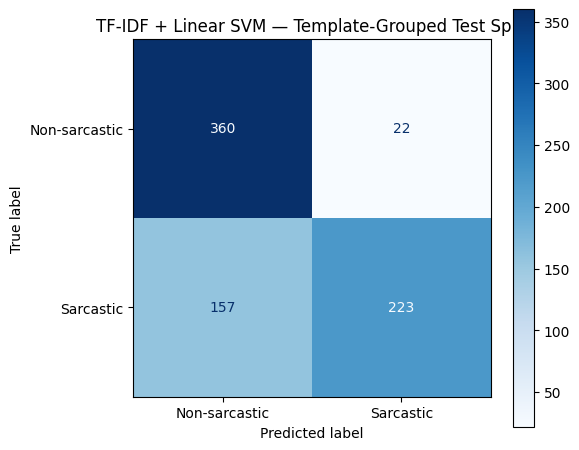


Model 2 complete.
Results saved to: /content/research_results/grouped_split/linear_svm


In [ ]:

# ============================================================
# MODEL 2: TF-IDF + LINEAR SVM
# Roman Urdu Sarcasm Detection
# SHARED TEMPLATE-GROUPED SPLIT
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. Configuration
SPLIT_DIR = "/content/research_results/shared_split"
OUTPUT_DIR = "/content/research_results/grouped_split/linear_svm"

RANDOM_STATE = 42
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 2. Load the shared grouped splits
train_df = pd.read_csv(f"{SPLIT_DIR}/train.csv")
val_df = pd.read_csv(f"{SPLIT_DIR}/validation.csv")
test_df = pd.read_csv(f"{SPLIT_DIR}/test.csv")

# 3. Validate required columns
for name, frame in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    required = ["Row_ID", "Text", "Final_Label", "Template_ID"]
    missing = [col for col in required if col not in frame.columns]

    if missing:
        raise ValueError(f"{name} split is missing columns: {missing}")

# 4. Check row IDs are disjoint
train_ids = set(train_df["Row_ID"])
val_ids = set(val_df["Row_ID"])
test_ids = set(test_df["Row_ID"])

assert train_ids.isdisjoint(val_ids), "Train/validation row overlap!"
assert train_ids.isdisjoint(test_ids), "Train/test row overlap!"
assert val_ids.isdisjoint(test_ids), "Validation/test row overlap!"

# 5. Check Template_ID groups are disjoint
train_groups = set(train_df["Template_ID"].dropna().astype(str))
val_groups = set(val_df["Template_ID"].dropna().astype(str))
test_groups = set(test_df["Template_ID"].dropna().astype(str))

assert train_groups.isdisjoint(val_groups), "Train/validation template overlap!"
assert train_groups.isdisjoint(test_groups), "Train/test template overlap!"
assert val_groups.isdisjoint(test_groups), "Validation/test template overlap!"

print("Row_ID overlap check: PASSED")
print("Template_ID overlap check: PASSED")

# 6. Prepare model inputs
def prepare_xy(frame, split_name):
    frame = frame.copy()

    frame["Text"] = frame["Text"].fillna("").astype(str).str.strip()

    if (frame["Text"] == "").any():
        raise ValueError(f"{split_name} contains empty text.")

    frame["Final_Label"] = pd.to_numeric(
        frame["Final_Label"], errors="raise"
    ).astype(int)

    if not set(frame["Final_Label"].unique()).issubset({0, 1}):
        raise ValueError(f"{split_name} labels must be 0 or 1.")

    return frame["Text"], frame["Final_Label"]


X_train, y_train = prepare_xy(train_df, "Train")
X_val, y_val = prepare_xy(val_df, "Validation")
X_test, y_test = prepare_xy(test_df, "Test")

print("\nSplit sizes:")
print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts().sort_index())

# 7. Build TF-IDF + Linear SVM pipeline
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="word",
        ngram_range=(1, 2),
        min_df=2,
        max_features=30000,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        C=1.0,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        max_iter=5000
    ))
])

# 8. Train ONLY on the shared training split
model.fit(X_train, y_train)

print("\nModel trained on the shared grouped training split.")

# 9. Evaluation function
def evaluate_model(model, X_eval, y_eval, split_name):
    predictions = model.predict(X_eval)

    metrics = {
        "Model": "TF-IDF + Linear SVM",
        "Split": split_name,
        "Accuracy": accuracy_score(y_eval, predictions),
        "Precision_macro": precision_score(
            y_eval, predictions, average="macro", zero_division=0
        ),
        "Recall_macro": recall_score(
            y_eval, predictions, average="macro", zero_division=0
        ),
        "Macro_F1": f1_score(
            y_eval, predictions, average="macro", zero_division=0
        )
    }

    print(f"\n{split_name.upper()} RESULTS")
    print(classification_report(
        y_eval,
        predictions,
        labels=[0, 1],
        target_names=["Non-sarcastic", "Sarcastic"],
        zero_division=0
    ))
    print("Metrics:", metrics)

    return metrics, predictions


# 10. Evaluate validation and test sets
val_metrics, val_predictions = evaluate_model(
    model, X_val, y_val, "validation"
)

test_metrics, test_predictions = evaluate_model(
    model, X_test, y_test, "test"
)

# 11. Save metrics
pd.DataFrame([val_metrics, test_metrics]).to_csv(
    os.path.join(OUTPUT_DIR, "metrics.csv"),
    index=False
)

# 12. Save predictions, including row IDs for traceability
prediction_df = test_df[["Row_ID", "Text", "Final_Label"]].copy()
prediction_df = prediction_df.rename(
    columns={"Final_Label": "True_Label"}
)
prediction_df["Predicted_Label"] = test_predictions

prediction_df.to_csv(
    os.path.join(OUTPUT_DIR, "test_predictions.csv"),
    index=False
)

# 13. Save confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=[0, 1],
    display_labels=["Non-sarcastic", "Sarcastic"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("TF-IDF + Linear SVM — Template-Grouped Test Split")
fig.tight_layout()

fig.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)
fig.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix.pdf"),
    bbox_inches="tight"
)
plt.show()

# 14. Save trained model
joblib.dump(
    model,
    os.path.join(OUTPUT_DIR, "linear_svm_model.joblib")
)

print("\nModel 2 complete.")
print("Results saved to:", OUTPUT_DIR)


Model 3

Row_ID separation: PASSED
Template_ID separation: PASSED

Split sizes:
Training examples: 3484
Validation examples: 754
Test examples: 762

Training label distribution:
Final_Label
0    1743
1    1741
Name: count, dtype: int64

Training Character n-gram TF-IDF + Linear SVM...

VALIDATION RESULTS
               precision    recall  f1-score   support

Non-sarcastic       0.61      0.69      0.65       375
    Sarcastic       0.65      0.56      0.60       379

     accuracy                           0.62       754
    macro avg       0.63      0.63      0.62       754
 weighted avg       0.63      0.62      0.62       754

Metrics: {'Model': 'Character n-gram TF-IDF + Linear SVM', 'Split': 'validation', 'Accuracy': 0.6246684350132626, 'Precision_macro': 0.6269725557461407, 'Recall_macro': 0.6250026385224274, 'Macro_F1': 0.6233267607075841}

TEST RESULTS
               precision    recall  f1-score   support

Non-sarcastic       0.64      0.95      0.77       382
    Sarcastic       0.90

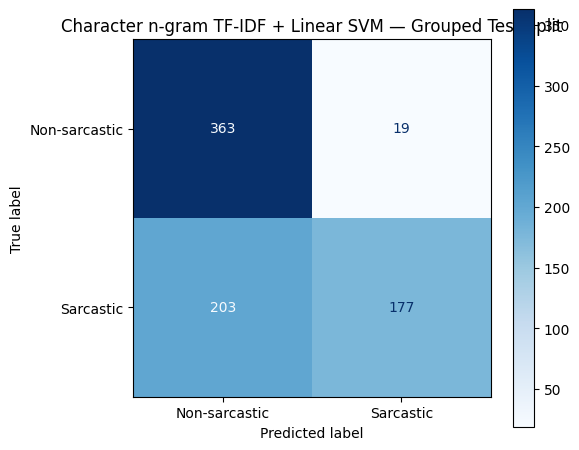


Model 3 completed successfully.
Results saved to: /content/research_results/grouped_split/char_ngram_svm

Saved files:
- char_ngram_svm_model.joblib
- confusion_matrix.pdf
- confusion_matrix.png
- metrics.csv
- test_predictions.csv


In [ ]:

# ============================================================
# MODEL 3: CHARACTER N-GRAM TF-IDF + LINEAR SVM
# Roman Urdu Sarcasm Detection Research
# SHARED TEMPLATE-GROUPED SPLIT
# ============================================================

import os
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. Configuration
SPLIT_DIR = "/content/research_results/shared_split"
OUTPUT_DIR = "/content/research_results/grouped_split/char_ngram_svm"
RANDOM_STATE = 42

os.makedirs(OUTPUT_DIR, exist_ok=True)

# 2. Load the SAME shared splits used by Models 1, 2 and 4
train_df = pd.read_csv(f"{SPLIT_DIR}/train.csv")
val_df = pd.read_csv(f"{SPLIT_DIR}/validation.csv")
test_df = pd.read_csv(f"{SPLIT_DIR}/test.csv")

# 3. Validate columns
for name, frame in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    required = ["Row_ID", "Text", "Final_Label", "Template_ID"]
    missing = [col for col in required if col not in frame.columns]

    if missing:
        raise ValueError(
            f"{name} split is missing columns: {missing}"
        )

# 4. Verify no row overlap
train_ids = set(train_df["Row_ID"])
val_ids = set(val_df["Row_ID"])
test_ids = set(test_df["Row_ID"])

assert train_ids.isdisjoint(val_ids), "Train/validation row overlap!"
assert train_ids.isdisjoint(test_ids), "Train/test row overlap!"
assert val_ids.isdisjoint(test_ids), "Validation/test row overlap!"

# 5. Verify no Template_ID overlap
train_groups = set(train_df["Template_ID"].dropna().astype(str))
val_groups = set(val_df["Template_ID"].dropna().astype(str))
test_groups = set(test_df["Template_ID"].dropna().astype(str))

assert train_groups.isdisjoint(val_groups), "Train/validation template overlap!"
assert train_groups.isdisjoint(test_groups), "Train/test template overlap!"
assert val_groups.isdisjoint(test_groups), "Validation/test template overlap!"

print("Row_ID separation: PASSED")
print("Template_ID separation: PASSED")

# 6. Prepare inputs and labels
def prepare_xy(frame, split_name):
    frame = frame.copy()

    frame["Text"] = frame["Text"].fillna("").astype(str).str.strip()

    if (frame["Text"] == "").any():
        raise ValueError(f"{split_name} contains empty text.")

    frame["Final_Label"] = pd.to_numeric(
        frame["Final_Label"], errors="raise"
    ).astype(int)

    if not set(frame["Final_Label"].unique()).issubset({0, 1}):
        raise ValueError(f"{split_name} labels must be 0 or 1.")

    return frame["Text"], frame["Final_Label"]


X_train, y_train = prepare_xy(train_df, "Train")
X_val, y_val = prepare_xy(val_df, "Validation")
X_test, y_test = prepare_xy(test_df, "Test")

print("\nSplit sizes:")
print("Training examples:", len(X_train))
print("Validation examples:", len(X_val))
print("Test examples:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts().sort_index())

# 7. Build character n-gram TF-IDF + Linear SVM
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=(2, 5),
        min_df=2,
        max_features=50000,
        sublinear_tf=True,
        lowercase=True
    )),
    ("classifier", LinearSVC(
        C=1.0,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        max_iter=5000
    ))
])

# 8. Train ONLY on the shared training split
print("\nTraining Character n-gram TF-IDF + Linear SVM...")
model.fit(X_train, y_train)

# 9. Evaluation function
def evaluate_model(model, X_eval, y_eval, split_name):
    predictions = model.predict(X_eval)

    metrics = {
        "Model": "Character n-gram TF-IDF + Linear SVM",
        "Split": split_name,
        "Accuracy": accuracy_score(y_eval, predictions),
        "Precision_macro": precision_score(
            y_eval, predictions,
            labels=[0, 1],
            average="macro",
            zero_division=0
        ),
        "Recall_macro": recall_score(
            y_eval, predictions,
            labels=[0, 1],
            average="macro",
            zero_division=0
        ),
        "Macro_F1": f1_score(
            y_eval, predictions,
            labels=[0, 1],
            average="macro",
            zero_division=0
        )
    }

    print(f"\n{split_name.upper()} RESULTS")
    print(classification_report(
        y_eval,
        predictions,
        labels=[0, 1],
        target_names=["Non-sarcastic", "Sarcastic"],
        zero_division=0
    ))

    print("Metrics:", metrics)
    return metrics, predictions


# 10. Evaluate validation and held-out test sets
val_metrics, val_predictions = evaluate_model(
    model, X_val, y_val, "validation"
)

test_metrics, test_predictions = evaluate_model(
    model, X_test, y_test, "test"
)

# 11. Save metrics
pd.DataFrame([val_metrics, test_metrics]).to_csv(
    os.path.join(OUTPUT_DIR, "metrics.csv"),
    index=False
)

# 12. Save test predictions with Row_ID for traceability
prediction_df = test_df[
    ["Row_ID", "Text", "Final_Label"]
].copy()

prediction_df = prediction_df.rename(
    columns={"Final_Label": "True_Label"}
)

prediction_df["Predicted_Label"] = test_predictions

prediction_df.to_csv(
    os.path.join(OUTPUT_DIR, "test_predictions.csv"),
    index=False
)

# 13. Save confusion matrix as PNG and PDF
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=[0, 1],
    display_labels=["Non-sarcastic", "Sarcastic"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title(
    "Character n-gram TF-IDF + Linear SVM — Grouped Test Split"
)
fig.tight_layout()

fig.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix.pdf"),
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# 14. Save trained model
joblib.dump(
    model,
    os.path.join(OUTPUT_DIR, "char_ngram_svm_model.joblib")
)

print("\nModel 3 completed successfully.")
print("Results saved to:", OUTPUT_DIR)
print("\nSaved files:")

for filename in sorted(os.listdir(OUTPUT_DIR)):
    print("-", filename)


Model 4

Device: CPU

Original columns:
Train: ['Row_ID', 'ID', 'Topic', 'Source_Group', 'Text', 'Canonical_Text', 'Final_Label', 'Label_Name', 'Sarcasm_Type', 'Content_Type', 'Variation_Level', 'Writer_Style', 'Variation_Types', 'Tokens_Changed', 'N_Tokens', 'Pct_Tokens_Changed', 'Has_Emoji', 'Group_ID', 'Template_ID', 'Suggested_Split']
Validation: ['Row_ID', 'ID', 'Topic', 'Source_Group', 'Text', 'Canonical_Text', 'Final_Label', 'Label_Name', 'Sarcasm_Type', 'Content_Type', 'Variation_Level', 'Writer_Style', 'Variation_Types', 'Tokens_Changed', 'N_Tokens', 'Pct_Tokens_Changed', 'Has_Emoji', 'Group_ID', 'Template_ID', 'Suggested_Split']
Test: ['Row_ID', 'ID', 'Topic', 'Source_Group', 'Text', 'Canonical_Text', 'Final_Label', 'Label_Name', 'Sarcasm_Type', 'Content_Type', 'Variation_Level', 'Writer_Style', 'Variation_Types', 'Tokens_Changed', 'N_Tokens', 'Pct_Tokens_Changed', 'Has_Emoji', 'Group_ID', 'Template_ID', 'Suggested_Split']

Row_ID overlap check: PASSED
Template_ID overlap check: PASSE

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/3484 [00:00<?, ? examples/s]

Map:   0%|          | 0/754 [00:00<?, ? examples/s]

Map:   0%|          | 0/762 [00:00<?, ? examples/s]

... (4 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

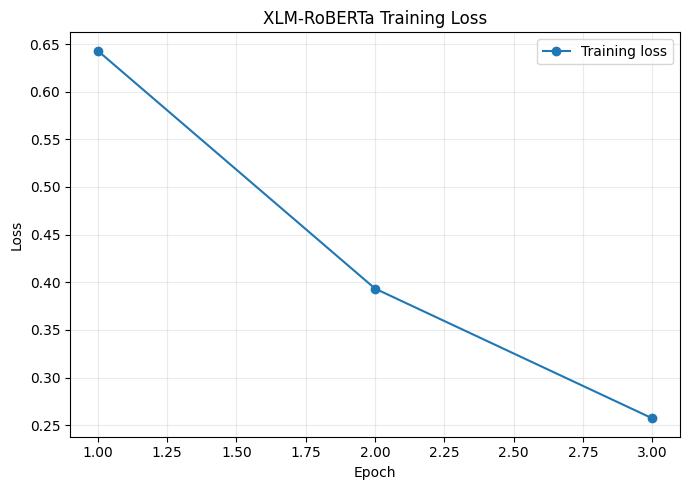

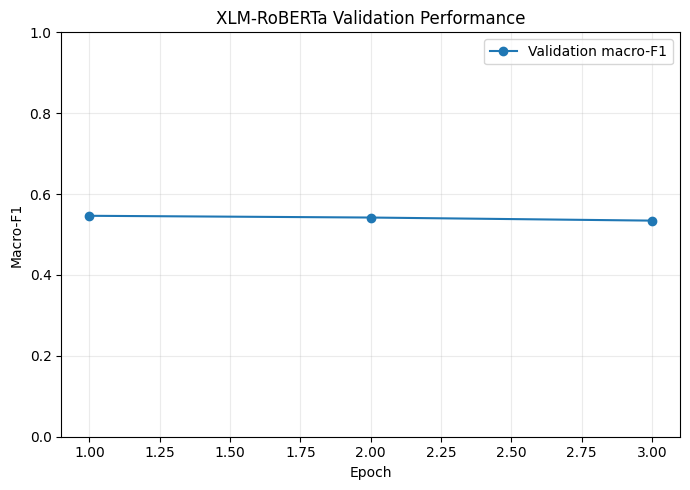

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,Macro Precision,Macro Recall,Macro F1
0.257226,1.028581,3,0.546419,0.546551,0.546505,0.546339


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,Macro Precision,Macro Recall,Macro F1
0.257226,0.749776,3,0.662730,0.665406,0.662559,0.661212



Validation results:
{'validation_loss': 1.0285807847976685, 'validation_accuracy': 0.5464190981432361, 'validation_macro_precision': 0.5465506919745043, 'validation_macro_recall': 0.546504837291117, 'validation_macro_f1': 0.5463393007937849}

Held-out test results:
{'test_loss': 0.7497760653495789, 'test_accuracy': 0.6627296587926509, 'test_macro_precision': 0.6654061025788407, 'test_macro_recall': 0.6625585560760541, 'test_macro_f1': 0.6612120551585263}


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



Test classification report:
               precision    recall  f1-score   support

Non-sarcastic       0.65      0.73      0.68       382
    Sarcastic       0.69      0.60      0.64       380

     accuracy                           0.66       762
    macro avg       0.67      0.66      0.66       762
 weighted avg       0.67      0.66      0.66       762



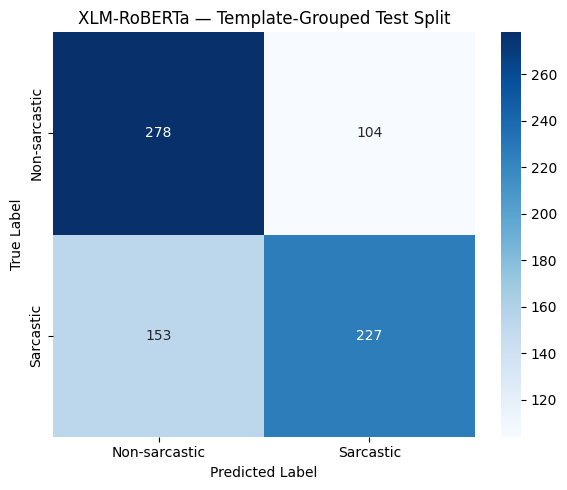

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


All outputs saved to: /content/research_results/grouped_split/xlmr
Best model saved to: /content/research_results/grouped_split/xlmr/best_model


In [ ]:

# ============================================================
# MODEL 4: XLM-RoBERTa on the SHARED TEMPLATE-GROUPED SPLIT
# Roman Urdu Sarcasm Detection
# ============================================================

# 1. Install dependencies
!pip -q install transformers datasets accelerate scikit-learn pandas matplotlib seaborn

# 2. Imports
import os
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

# 3. Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Device:", "GPU" if torch.cuda.is_available() else "CPU")

# 4. Paths
SPLIT_DIR = "/content/research_results/shared_split"

# Keep grouped-split results separate from previous random-split results.
OUT_DIR = "/content/research_results/grouped_split/xlmr"
os.makedirs(OUT_DIR, exist_ok=True)

TRAIN_PATH = os.path.join(SPLIT_DIR, "train.csv")
VAL_PATH = os.path.join(SPLIT_DIR, "validation.csv")
TEST_PATH = os.path.join(SPLIT_DIR, "test.csv")

# 5. Load the SAME shared splits used by Models 1–3
for path in [TRAIN_PATH, VAL_PATH, TEST_PATH]:
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Split file not found: {path}\n"
            "Run the shared template-grouped split creation code first."
        )

train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)
test_df = pd.read_csv(TEST_PATH)

print("\nOriginal columns:")
print("Train:", train_df.columns.tolist())
print("Validation:", val_df.columns.tolist())
print("Test:", test_df.columns.tolist())

# 6. Validate columns and fix the KeyError
# Shared split files normally contain Final_Label, not labels.
def prepare_split(frame, split_name):
    frame = frame.copy()

    required = ["Text", "Final_Label"]
    missing = [col for col in required if col not in frame.columns]

    if missing:
        raise ValueError(
            f"{split_name} is missing columns {missing}. "
            f"Available columns: {frame.columns.tolist()}"
        )

    # Clean text without independently dropping rows or duplicates.
    frame["Text"] = frame["Text"].fillna("").astype(str).str.strip()

    if (frame["Text"] == "").any():
        raise ValueError(
            f"{split_name} contains empty texts. "
            "Fix the shared split files and recreate the splits consistently."
        )

    frame["Final_Label"] = pd.to_numeric(
        frame["Final_Label"], errors="raise"
    ).astype(int)

    if not set(frame["Final_Label"].unique()).issubset({0, 1}):
        raise ValueError(
            f"{split_name}: Final_Label must contain only 0 and 1."
        )

    # Hugging Face Trainer expects the target column named 'labels'.
    frame = frame.rename(columns={"Final_Label": "labels"})

    return frame.reset_index(drop=True)


train_df = prepare_split(train_df, "Train")
val_df = prepare_split(val_df, "Validation")
test_df = prepare_split(test_df, "Test")

# 7. Verify no row overlap between splits
# Row_ID should be available in the shared split files.
if all("Row_ID" in frame.columns
       for frame in [train_df, val_df, test_df]):

    train_ids = set(train_df["Row_ID"])
    val_ids = set(val_df["Row_ID"])
    test_ids = set(test_df["Row_ID"])

    assert train_ids.isdisjoint(val_ids), "Train/validation row overlap!"
    assert train_ids.isdisjoint(test_ids), "Train/test row overlap!"
    assert val_ids.isdisjoint(test_ids), "Validation/test row overlap!"

    print("\nRow_ID overlap check: PASSED")

# Verify that Template_ID groups do not cross splits.
if all("Template_ID" in frame.columns
       for frame in [train_df, val_df, test_df]):

    train_groups = set(train_df["Template_ID"].dropna().astype(str))
    val_groups = set(val_df["Template_ID"].dropna().astype(str))
    test_groups = set(test_df["Template_ID"].dropna().astype(str))

    assert train_groups.isdisjoint(val_groups), \
        "Template_ID overlap between train and validation!"
    assert train_groups.isdisjoint(test_groups), \
        "Template_ID overlap between train and test!"
    assert val_groups.isdisjoint(test_groups), \
        "Template_ID overlap between validation and test!"

    print("Template_ID overlap check: PASSED")
else:
    print(
        "WARNING: Template_ID not found in every split. "
        "Confirm grouping was verified during split creation."
    )

print("\nSplit sizes:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nTraining label distribution:")
print(train_df["labels"].value_counts().sort_index())

print("\nValidation label distribution:")
print(val_df["labels"].value_counts().sort_index())

print("\nTest label distribution:")
print(test_df["labels"].value_counts().sort_index())

# Check both classes exist in every split.
for name, frame in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    if set(frame["labels"].unique()) != {0, 1}:
        raise ValueError(
            f"{name} must contain both classes 0 and 1."
        )

# 8. Load XLM-RoBERTa
MODEL_NAME = "xlm-roberta-base"
MAX_LENGTH = 128

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={0: "Non-sarcastic", 1: "Sarcastic"},
    label2id={"Non-sarcastic": 0, "Sarcastic": 1}
)

# 9. Convert the shared splits into Hugging Face datasets
def tokenize_batch(batch):
    return tokenizer(
        batch["Text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

def to_hf_dataset(frame):
    # Keep only the model input and target columns.
    hf_df = frame[["Text", "labels"]].copy()

    dataset = Dataset.from_pandas(
        hf_df,
        preserve_index=False
    )

    return dataset.map(
        tokenize_batch,
        batched=True
    )

train_ds = to_hf_dataset(train_df)
val_ds = to_hf_dataset(val_df)
test_ds = to_hf_dataset(test_df)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# 10. Evaluation metrics
def compute_metrics(eval_pred):
    logits = eval_pred.predictions
    labels = eval_pred.label_ids

    # Some model outputs may be returned as a tuple.
    if isinstance(logits, tuple):
        logits = logits[0]

    predictions = np.argmax(logits, axis=-1)

    precision, recall, macro_f1, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            labels=[0, 1],
            average="macro",
            zero_division=0
        )
    )

    accuracy = accuracy_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": macro_f1
    }

# 11. Training configuration


training_args = TrainingArguments(
    output_dir=f"{OUT_DIR}/checkpoints",

    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",

    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,

    load_best_model_at_end=True,
    metric_for_best_model="eval_macro_f1",
    greater_is_better=True,

    save_total_limit=2,
    seed=SEED,
    data_seed=SEED,

    fp16=torch.cuda.is_available(),
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Training configuration created successfully.")



# 12. Train from the pretrained model on the grouped training split
print("\nStarting XLM-RoBERTa training...")
trainer.train()

# Add after trainer.train() in the XLM-RoBERTa section.

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUT_DIR = Path("/content/research_results/grouped_split/xlmr")
OUT_DIR.mkdir(parents=True, exist_ok=True)

history = pd.DataFrame(trainer.state.log_history)
history.to_csv(OUT_DIR / "training_history.csv", index=False)

# Plot training loss
if "loss" in history.columns:
    train_loss = history.dropna(subset=["loss"])

    if not train_loss.empty:
        fig, ax = plt.subplots(figsize=(7, 5))
        ax.plot(
            train_loss["epoch"],
            train_loss["loss"],
            marker="o",
            label="Training loss"
        )
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss")
        ax.set_title("XLM-RoBERTa Training Loss")
        ax.grid(alpha=0.25)
        ax.legend()
        fig.tight_layout()
        fig.savefig(
            OUT_DIR / "training_loss.png",
            dpi=300,
            bbox_inches="tight"
        )
        fig.savefig(
            OUT_DIR / "training_loss.pdf",
            bbox_inches="tight"
        )
        plt.show()
        plt.close(fig)

# Plot validation macro-F1 by epoch
if "eval_macro_f1" in history.columns:
    val_history = history.dropna(subset=["eval_macro_f1"])

    if not val_history.empty:
        fig, ax = plt.subplots(figsize=(7, 5))
        ax.plot(
            val_history["epoch"],
            val_history["eval_macro_f1"],
            marker="o",
            label="Validation macro-F1"
        )
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Macro-F1")
        ax.set_ylim(0, 1)
        ax.set_title("XLM-RoBERTa Validation Performance")
        ax.grid(alpha=0.25)
        ax.legend()
        fig.tight_layout()
        fig.savefig(
            OUT_DIR / "validation_macro_f1.png",
            dpi=300,
            bbox_inches="tight"
        )
        fig.savefig(
            OUT_DIR / "validation_macro_f1.pdf",
            bbox_inches="tight"
        )
        plt.show()
        plt.close(fig)



# 13. Evaluate on validation and held-out test splits
val_results = trainer.evaluate(
    eval_dataset=val_ds,
    metric_key_prefix="validation"
)

test_results = trainer.evaluate(
    eval_dataset=test_ds,
    metric_key_prefix="test"
)

print("\nValidation results:")
print(val_results)

print("\nHeld-out test results:")
print(test_results)

# 14. Obtain final test predictions
prediction_output = trainer.predict(
    test_ds,
    metric_key_prefix="test"
)

y_true = prediction_output.label_ids
logits = prediction_output.predictions

if isinstance(logits, tuple):
    logits = logits[0]

y_pred = np.argmax(logits, axis=-1)

print("\nTest classification report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Non-sarcastic", "Sarcastic"],
        zero_division=0
    )
)

# 15. Save metrics
precision, recall, macro_f1, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=[0, 1],
    average="macro",
    zero_division=0
)

metrics = {
    "model": "XLM-RoBERTa-base",
    "split_method": "Template-grouped shared split",
    "seed": SEED,
    "max_length": MAX_LENGTH,
    "epochs": 3,
    "train_size": len(train_df),
    "validation_size": len(val_df),
    "test_size": len(test_df),
    "test_accuracy": accuracy_score(y_true, y_pred),
    "test_macro_precision": precision,
    "test_macro_recall": recall,
    "test_macro_f1": macro_f1,
    "best_checkpoint": trainer.state.best_model_checkpoint
}

pd.DataFrame([metrics]).to_csv(
    f"{OUT_DIR}/metrics.csv",
    index=False
)

# Save detailed evaluation results too.
pd.DataFrame([
    {"split": "validation", **val_results},
    {"split": "test", **test_results}
]).to_csv(
    f"{OUT_DIR}/evaluation_results.csv",
    index=False
)

# 16. Save predictions with original tracking columns when available
prediction_df = test_df.copy()
prediction_df["True_Label"] = y_true
prediction_df["Predicted_Label"] = y_pred

prediction_df.to_csv(
    f"{OUT_DIR}/test_predictions.csv",
    index=False
)

# 17. Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-sarcastic", "Sarcastic"],
    yticklabels=["Non-sarcastic", "Sarcastic"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("XLM-RoBERTa — Template-Grouped Test Split")
plt.tight_layout()

plt.savefig(
    f"{OUT_DIR}/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    f"{OUT_DIR}/confusion_matrix.pdf",
    bbox_inches="tight"
)
plt.show()

# 18. Save the best fine-tuned model and tokenizer
BEST_MODEL_DIR = f"{OUT_DIR}/best_model"
trainer.save_model(BEST_MODEL_DIR)
tokenizer.save_pretrained(BEST_MODEL_DIR)

print("\nAll outputs saved to:", OUT_DIR)
print("Best model saved to:", BEST_MODEL_DIR)


                            Model  Accuracy  Macro_Precision  Macro_Recall  Macro_F1  N_Test
Word TF-IDF + Logistic Regression  0.729659         0.752244      0.729264  0.723245     762
         Word TF-IDF + Linear SVM  0.765092         0.803265      0.764625  0.757245     762
    Character TF-IDF + Linear SVM  0.708661         0.772202      0.708026  0.690203     762
                      XLM-RoBERTa  0.662730         0.665406      0.662559  0.661212     762


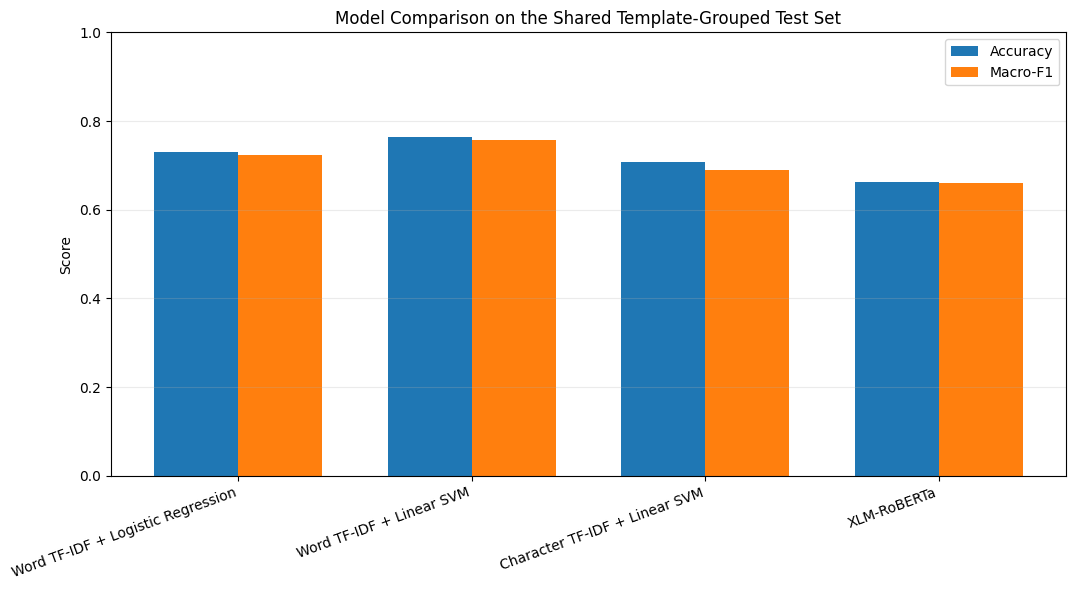

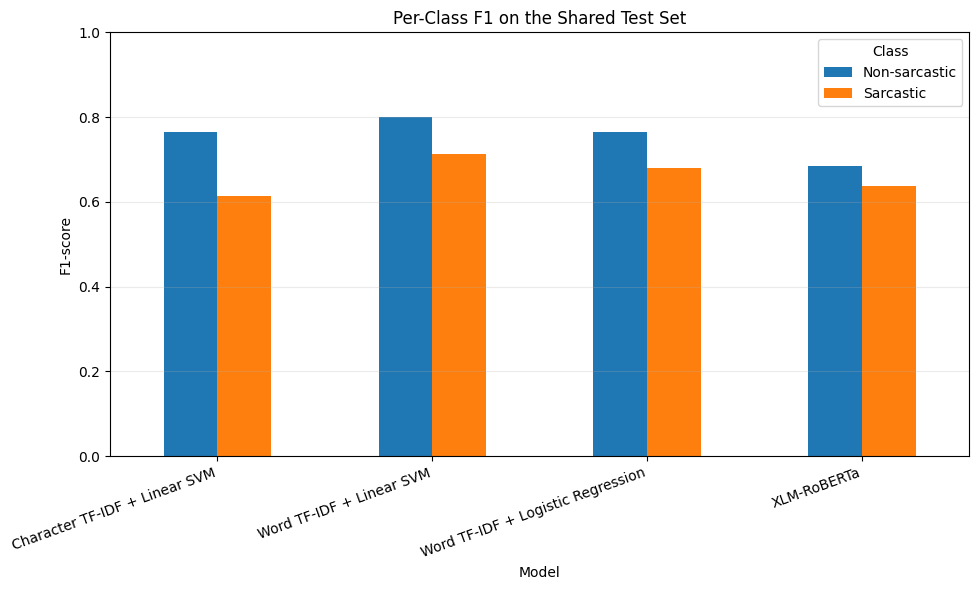


Comparison files saved to: /content/research_results/grouped_split/comparison


In [ ]:

# ============================================================
# CROSS-MODEL EVALUATION AND PUBLICATION FIGURES
# Run only after all four models have clean saved predictions.
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

BASE = Path("/content/research_results/grouped_split")
OUT = BASE / "comparison"
OUT.mkdir(parents=True, exist_ok=True)

prediction_paths = {
    "Word TF-IDF + Logistic Regression":
        BASE / "logistic_regression" / "test_predictions.csv",

    "Word TF-IDF + Linear SVM":
        BASE / "linear_svm" / "test_predictions.csv",

    "Character TF-IDF + Linear SVM":
        BASE / "char_ngram_svm" / "test_predictions.csv",

    "XLM-RoBERTa":
        BASE / "xlmr" / "test_predictions.csv",
}

test_df = pd.read_csv(
    "/content/research_results/shared_split/test.csv"
)

if "Row_ID" not in test_df.columns:
    raise ValueError("Shared test split must contain Row_ID.")

if test_df["Row_ID"].duplicated().any():
    raise ValueError("Duplicate Row_ID in shared test split.")

expected_ids = set(test_df["Row_ID"])
expected_labels = test_df.set_index("Row_ID")["Final_Label"]

summary = []
class_rows = []
all_predictions = {}

for model_name, path in prediction_paths.items():
    if not path.exists():
        raise FileNotFoundError(
            f"Missing predictions for {model_name}: {path}"
        )

    pred = pd.read_csv(path)

    required = {"Row_ID", "Predicted_Label"}
    missing = required - set(pred.columns)
    if missing:
        raise ValueError(
            f"{model_name}: missing prediction columns {missing}. "
            "Correct the model's prediction-saving code."
        )

    if "True_Label" in pred.columns:
        true_col = "True_Label"
    elif "Final_Label" in pred.columns:
        true_col = "Final_Label"
    else:
        raise ValueError(f"{model_name}: no true-label column.")

    if pred["Row_ID"].duplicated().any():
        raise ValueError(f"{model_name}: duplicate Row_ID values.")

    if set(pred["Row_ID"]) != expected_ids:
        raise ValueError(
            f"{model_name}: prediction Row_IDs do not match "
            "the shared test split."
        )

    pred = pred.copy()
    pred["True_Label"] = pd.to_numeric(
        pred[true_col], errors="raise"
    ).astype(int)
    pred["Predicted_Label"] = pd.to_numeric(
        pred["Predicted_Label"], errors="raise"
    ).astype(int)

    if not set(pred["Predicted_Label"].unique()).issubset({0, 1}):
        raise ValueError(f"{model_name}: invalid predicted labels.")

    pred = pred.sort_values("Row_ID").reset_index(drop=True)

    expected_true = pred["Row_ID"].map(expected_labels).to_numpy()
    if not np.array_equal(pred["True_Label"].to_numpy(), expected_true):
        raise ValueError(
            f"{model_name}: saved true labels do not match test.csv."
        )

    y_true = pred["True_Label"]
    y_pred = pred["Predicted_Label"]

    summary.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro_Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro_Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro_F1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "N_Test": len(pred)
    })

    report = classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Non-sarcastic", "Sarcastic"],
        output_dict=True,
        zero_division=0
    )

    for class_name in ["Non-sarcastic", "Sarcastic"]:
        class_rows.append({
            "Model": model_name,
            "Class": class_name,
            "Precision": report[class_name]["precision"],
            "Recall": report[class_name]["recall"],
            "F1": report[class_name]["f1-score"],
            "Support": report[class_name]["support"]
        })

    all_predictions[model_name] = pred[
        ["Row_ID", "True_Label", "Predicted_Label"]
    ].copy()

summary_df = pd.DataFrame(summary)
class_df = pd.DataFrame(class_rows)

summary_df.to_csv(OUT / "model_comparison_metrics.csv", index=False)
class_df.to_csv(OUT / "classwise_metrics.csv", index=False)

print(summary_df.to_string(index=False))

# Figure 1: accuracy and macro-F1 comparison
fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(summary_df))
width = 0.36

ax.bar(
    x - width / 2,
    summary_df["Accuracy"],
    width,
    label="Accuracy"
)
ax.bar(
    x + width / 2,
    summary_df["Macro_F1"],
    width,
    label="Macro-F1"
)

ax.set_xticks(x)
ax.set_xticklabels(summary_df["Model"], rotation=20, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Model Comparison on the Shared Template-Grouped Test Set")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()

fig.savefig(OUT / "model_comparison.png", dpi=300, bbox_inches="tight")
fig.savefig(OUT / "model_comparison.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)

# Figure 2: per-class F1 comparison
pivot = class_df.pivot(
    index="Model",
    columns="Class",
    values="F1"
)

fig, ax = plt.subplots(figsize=(10, 6))
pivot.plot(kind="bar", ax=ax)

ax.set_ylabel("F1-score")
ax.set_ylim(0, 1)
ax.set_title("Per-Class F1 on the Shared Test Set")
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()

fig.savefig(OUT / "per_class_f1.png", dpi=300, bbox_inches="tight")
fig.savefig(OUT / "per_class_f1.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)

print("\nComparison files saved to:", OUT)


Test examples: 762
Label counts: {0: 382, 1: 380}

Perturbation coverage:
         Level  Examples_Changed  Total_Examples  Percent_Examples_Changed
      Original                 0             762                  0.000000
    Mild (25%)               160             762                 20.997375
Moderate (50%)               286             762                 37.532808
 Strong (100%)               426             762                 55.905512

Review spelling_variation_examples_for_review.csv before interpreting the results. Check that meaning and labels are preserved.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


XLM-R device: cpu

Evaluating: Original

Evaluating: Mild (25%)

Evaluating: Moderate (50%)

Evaluating: Strong (100%)

Macro-F1 results:
Model           Character TF-IDF + Linear SVM  Word TF-IDF + Linear SVM  Word TF-IDF + Logistic Regression  XLM-RoBERTa
Level                                                                                                                  
Mild (25%)                           0.686983                  0.761197                           0.725706     0.649157
Moderate (50%)                       0.690530                  0.762199                           0.730628     0.653569
Original                             0.690203                  0.757245                           0.723245     0.661212
Strong (100%)                        0.692458                  0.768877                           0.735786     0.643756


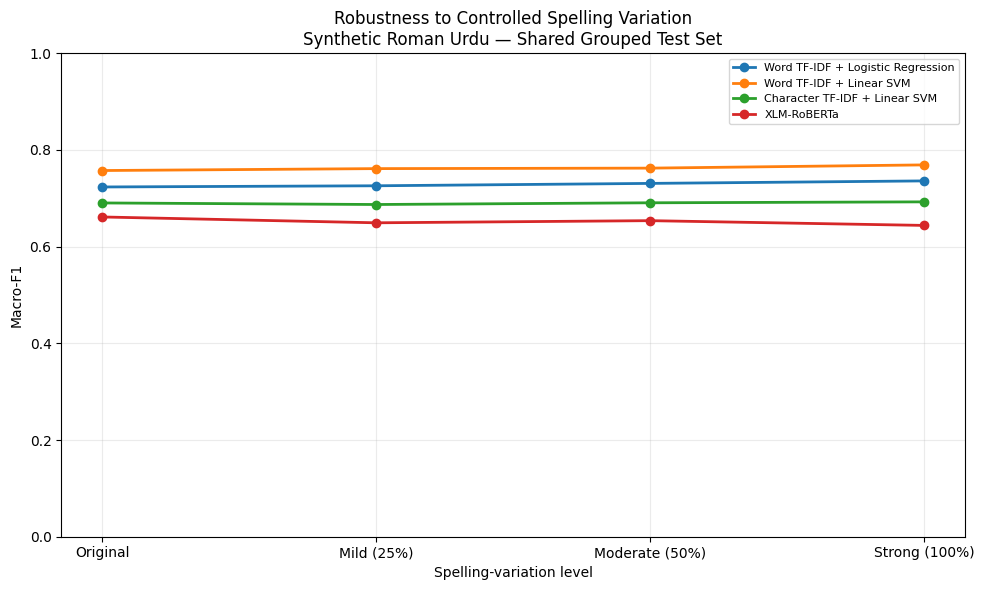


All robustness results saved to: /content/research_results/grouped_split/spelling_robustness
Figure B: figure_B_robustness_curve.png
Figure B: figure_B_robustness_curve.pdf


In [ ]:

# ============================================================
# FIGURE B: SPELLING-VARIATION ROBUSTNESS EXPERIMENT
# Uses the shared TEMPLATE-GROUPED test set for all 4 models.
# Add after Cell 12 (Model 4 grouped-split training).
# ============================================================

from pathlib import Path
import hashlib
import re
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

from transformers import AutoTokenizer, AutoModelForSequenceClassification

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

BASE = Path("/content/research_results/grouped_split")
SPLIT_DIR = Path("/content/research_results/shared_split")
OUT_DIR = BASE / "spelling_robustness"

OUT_DIR.mkdir(parents=True, exist_ok=True)

TEST_PATH = SPLIT_DIR / "test.csv"

MODEL_PATHS = {
    "Word TF-IDF + Logistic Regression":
        BASE / "logistic_regression" / "logistic_regression_model.joblib",

    "Word TF-IDF + Linear SVM":
        BASE / "linear_svm" / "linear_svm_model.joblib",

    "Character TF-IDF + Linear SVM":
        BASE / "char_ngram_svm" / "char_ngram_svm_model.joblib",

    "XLM-RoBERTa":
        BASE / "xlmr" / "best_model",
}

if not TEST_PATH.exists():
    raise FileNotFoundError(f"Missing shared test set: {TEST_PATH}")

for name, path in MODEL_PATHS.items():
    if not path.exists():
        raise FileNotFoundError(
            f"Missing saved model for {name}: {path}\n"
            "Train and save this model using the grouped split first."
        )

test_df = pd.read_csv(TEST_PATH)

required_cols = {"Row_ID", "Text", "Final_Label"}
missing = required_cols - set(test_df.columns)

if missing:
    raise ValueError(f"Missing test columns: {missing}")

if test_df["Row_ID"].duplicated().any():
    raise ValueError("Duplicate Row_ID values in test set.")

if test_df["Text"].isna().any():
    raise ValueError("Missing text in test set.")

if test_df["Final_Label"].isna().any():
    raise ValueError("Missing labels in test set.")

y_true = test_df["Final_Label"].astype(int).to_numpy()

if not set(np.unique(y_true)).issubset({0, 1}):
    raise ValueError("Expected binary labels 0 and 1.")

original_texts = test_df["Text"].astype(str).tolist()

print("Test examples:", len(test_df))
print("Label counts:", pd.Series(y_true).value_counts().sort_index().to_dict())


# ------------------------------------------------------------
# 2. Define spelling-variation rules
# ------------------------------------------------------------


SPELLING_MAP = {
    "hai": "hy",
    "hain": "hen",
    "nahi": "nai",
    "nahin": "nhi",
    "bohat": "bht",
    "bahut": "bht",
    "kya": "kia",
    "kyun": "q",
    "mujhe": "mjy",
    "tum": "tm",
    "raha": "rha",
    "rahi": "rhi",
    "kar": "kr",
    "acha": "acha",
    "achha": "acha",
}

# Use the following perturbation levels:
# 0% = original text
# 25% = alter 25% of eligible word occurrences
# 50% = alter 50% of eligible word occurrences
# 100% = alter all eligible word occurrences

LEVELS = {
    "Original": 0.00,
    "Mild (25%)": 0.25,
    "Moderate (50%)": 0.50,
    "Strong (100%)": 1.00,
}



# ------------------------------------------------------------
# 3. Deterministic spelling perturbation
# ------------------------------------------------------------

TOKEN_PATTERN = re.compile(r"\b[A-Za-z]+\b")

def stable_fraction(row_id, token_position):
    """Stable pseudo-random value for reproducible perturbations."""
    key = f"{row_id}|{token_position}".encode("utf-8")
    digest = hashlib.sha256(key).digest()
    integer = int.from_bytes(digest[:8], "big")
    return integer / (2**64)


def perturb_text(text, row_id, fraction):

    if fraction <= 0:
        return str(text)

    text = str(text)
    token_position = 0

    def replace_match(match):
        nonlocal token_position

        original_word = match.group(0)
        lookup = original_word.lower()
        position = token_position
        token_position += 1

        if lookup not in SPELLING_MAP:
            return original_word

        if stable_fraction(row_id, position) >= fraction:
            return original_word

        replacement = SPELLING_MAP[lookup]

        # Preserve initial capitalization when applicable.
        if original_word[:1].isupper():
            replacement = replacement.capitalize()

        return replacement

    return TOKEN_PATTERN.sub(replace_match, text)


variant_texts = {}
variant_coverage = []

for level_name, fraction in LEVELS.items():
    texts = [
        perturb_text(text, row_id, fraction)
        for text, row_id in zip(original_texts, test_df["Row_ID"])
    ]

    variant_texts[level_name] = texts

    changed = sum(
        before != after
        for before, after in zip(original_texts, texts)
    )

    variant_coverage.append({
        "Level": level_name,
        "Examples_Changed": changed,
        "Total_Examples": len(texts),
        "Percent_Examples_Changed": 100 * changed / len(texts)
    })

coverage_df = pd.DataFrame(variant_coverage)
coverage_df.to_csv(
    OUT_DIR / "perturbation_coverage.csv",
    index=False
)

print("\nPerturbation coverage:")
print(coverage_df.to_string(index=False))

# Save examples for manual linguistic and label-validity review.
examples = test_df[["Row_ID", "Text", "Final_Label"]].copy()

for level_name, texts in variant_texts.items():
    examples[level_name] = texts

examples.to_csv(
    OUT_DIR / "spelling_variation_examples_for_review.csv",
    index=False
)

print(
    "\nReview spelling_variation_examples_for_review.csv before "
    "interpreting the results. Check that meaning and labels are preserved."
)


# ------------------------------------------------------------
# 4. Load the saved sklearn pipelines
# ------------------------------------------------------------

sklearn_models = {}

for name in [
    "Word TF-IDF + Logistic Regression",
    "Word TF-IDF + Linear SVM",
    "Character TF-IDF + Linear SVM",
]:
    sklearn_models[name] = joblib.load(MODEL_PATHS[name])


# ------------------------------------------------------------
# 5. Load XLM-RoBERTa from its saved best checkpoint
# ------------------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

xlmr_dir = MODEL_PATHS["XLM-RoBERTa"]

xlmr_tokenizer = AutoTokenizer.from_pretrained(str(xlmr_dir))
xlmr_model = AutoModelForSequenceClassification.from_pretrained(
    str(xlmr_dir)
)

xlmr_model.to(device)
xlmr_model.eval()

print("\nXLM-R device:", device)


def predict_xlmr(texts, batch_size=16):
    predictions = []

    for start in range(0, len(texts), batch_size):
        batch_texts = texts[start:start + batch_size]

        encoded = xlmr_tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=256,
            return_tensors="pt"
        )

        encoded = {
            key: value.to(device)
            for key, value in encoded.items()
        }

        with torch.no_grad():
            logits = xlmr_model(**encoded).logits

        predictions.extend(
            logits.argmax(dim=1).cpu().numpy().tolist()
        )

    return np.asarray(predictions, dtype=int)




# ------------------------------------------------------------
# 6. Evaluate all models at every perturbation level
# ------------------------------------------------------------

metric_rows = []
prediction_frames = []

for level_name, texts in variant_texts.items():
    print(f"\nEvaluating: {level_name}")

    for model_name, model in sklearn_models.items():
        predictions = model.predict(texts).astype(int)

        metrics = {
            "Model": model_name,
            "Level": level_name,
            "Accuracy": accuracy_score(y_true, predictions),
            "Macro_Precision": precision_score(
                y_true, predictions,
                average="macro", zero_division=0
            ),
            "Macro_Recall": recall_score(
                y_true, predictions,
                average="macro", zero_division=0
            ),
            "Macro_F1": f1_score(
                y_true, predictions,
                average="macro", zero_division=0
            ),
        }

        metric_rows.append(metrics)

        prediction_frames.append(pd.DataFrame({
            "Row_ID": test_df["Row_ID"].to_numpy(),
            "True_Label": y_true,
            "Predicted_Label": predictions,
            "Model": model_name,
            "Level": level_name,
            "Text": texts,
        }))

    # Evaluate XLM-R on the exact same variant examples.
    predictions = predict_xlmr(texts)

    metric_rows.append({
        "Model": "XLM-RoBERTa",
        "Level": level_name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Macro_Precision": precision_score(
            y_true, predictions,
            average="macro", zero_division=0
        ),
        "Macro_Recall": recall_score(
            y_true, predictions,
            average="macro", zero_division=0
        ),
        "Macro_F1": f1_score(
            y_true, predictions,
            average="macro", zero_division=0
        ),
    })

    prediction_frames.append(pd.DataFrame({
        "Row_ID": test_df["Row_ID"].to_numpy(),
        "True_Label": y_true,
        "Predicted_Label": predictions,
        "Model": "XLM-RoBERTa",
        "Level": level_name,
        "Text": texts,
    }))


metrics_df = pd.DataFrame(metric_rows)

metrics_df.to_csv(
    OUT_DIR / "spelling_robustness_metrics.csv",
    index=False
)

predictions_df = pd.concat(
    prediction_frames,
    ignore_index=True
)

predictions_df.to_csv(
    OUT_DIR / "spelling_robustness_predictions.csv",
    index=False
)

print("\nMacro-F1 results:")
print(
    metrics_df.pivot(
        index="Level",
        columns="Model",
        values="Macro_F1"
    ).to_string()
)


# ------------------------------------------------------------
# 7. Figure B: Macro-F1 robustness curve
# ------------------------------------------------------------

level_order = list(LEVELS.keys())

fig, ax = plt.subplots(figsize=(10, 6))

for model_name in metrics_df["Model"].unique():
    subset = (
        metrics_df[metrics_df["Model"] == model_name]
        .set_index("Level")
        .reindex(level_order)
    )

    ax.plot(
        range(len(level_order)),
        subset["Macro_F1"],
        marker="o",
        linewidth=2,
        label=model_name
    )

ax.set_xticks(range(len(level_order)))
ax.set_xticklabels(level_order)
ax.set_xlabel("Spelling-variation level")
ax.set_ylabel("Macro-F1")
ax.set_ylim(0, 1)
ax.set_title(
    "Robustness to Controlled Spelling Variation\n"
    "Synthetic Roman Urdu — Shared Grouped Test Set"
)
ax.grid(alpha=0.25)
ax.legend(loc="best", fontsize=8)
fig.tight_layout()

fig.savefig(
    OUT_DIR / "figure_B_robustness_curve.png",
    dpi=300,
    bbox_inches="tight"
)
fig.savefig(
    OUT_DIR / "figure_B_robustness_curve.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 8. Calculate change from original baseline
# ------------------------------------------------------------

baseline = (
    metrics_df[metrics_df["Level"] == "Original"]
    [["Model", "Macro_F1"]]
    .rename(columns={"Macro_F1": "Original_Macro_F1"})
)

degradation = metrics_df.merge(baseline, on="Model")

degradation["Delta_Macro_F1"] = (
    degradation["Macro_F1"] - degradation["Original_Macro_F1"]
)

degradation.to_csv(
    OUT_DIR / "robustness_degradation.csv",
    index=False
)

print("\nAll robustness results saved to:", OUT_DIR)
print("Figure B: figure_B_robustness_curve.png")
print("Figure B: figure_B_robustness_curve.pdf")


Files included: 44
ZIP size: 5.64 MB
Starting download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

four models: Word TF-IDF + LR, Word TF-IDF + SVM, Char TF-IDF + SVM, and the combined Word+Char TF-IDF + SVM.

In [ ]:
# Paste this into a NEW cell in Google Colab and run it AFTER the training cell.
# It builds summary tables from /content/group_split_results.csv, saves them as one
# Excel file plus separate CSV files, zips everything, and downloads the zip to your laptop.

import os
import zipfile

import pandas as pd
from google.colab import files

SRC = "/content/group_split_results.csv"
OUT_DIR = "/content/saved_results"
os.makedirs(OUT_DIR, exist_ok=True)

res = pd.read_csv(SRC)

wanted = ["ALL", "Standard", "Light", "Moderate", "Heavy"]
cols = [c for c in wanted if c in set(res["subset"])]
metrics = ["accuracy", "macro_f1", "sarcastic_f1", "sarcastic_recall", "non_sarcastic_recall"]


def std0(s):  # same std as the training script (ddof=0)
    return s.std(ddof=0)


tables = {"raw_results": res}

# Mean and std over seeds, per model and per variation level
for m in metrics:
    mean = res.pivot_table(index="model", columns="subset", values=m, aggfunc="mean")[cols].round(4)
    std = res.pivot_table(index="model", columns="subset", values=m, aggfunc=std0)[cols].round(4)
    tables[f"{m}_mean"] = mean.reset_index()
    tables[f"{m}_std"] = std.reset_index()

# Combined "mean ± std" table for the paper (macro-F1 and sarcastic recall)
for m in ["macro_f1", "sarcastic_recall"]:
    mean = res.pivot_table(index="model", columns="subset", values=m, aggfunc="mean")[cols]
    std = res.pivot_table(index="model", columns="subset", values=m, aggfunc=std0)[cols]
    tables[f"{m}_mean_pm_std"] = (mean.round(3).astype(str) + " ± " + std.round(3).astype(str)).reset_index()

# Per-seed overall macro-F1 (shows how much the result depends on the split)
per_seed = (
    res[res["subset"] == "ALL"]
    .pivot_table(index="seed", columns="model", values="macro_f1")
    .round(4)
    .reset_index()
)
tables["per_seed_macro_f1_ALL"] = per_seed

# Chosen C and validation macro-F1 per seed
tables["best_C_and_val_f1"] = (
    res[res["subset"] == "ALL"][["seed", "model", "best_C", "val_macro_f1"]]
    .round(4)
    .sort_values(["seed", "model"])
    .reset_index(drop=True)
)

# Sample counts per variation level and seed (useful for the paper's limitations section)
tables["test_sample_counts"] = (
    res.pivot_table(index=["seed", "model"], columns="subset", values="n", aggfunc="first")[cols]
    .reset_index()
)

# Standard -> Heavy drop (positive = performance fell, negative = performance rose)
if {"Standard", "Heavy"} <= set(cols):
    piv = res.pivot_table(index="model", columns="subset", values="macro_f1", aggfunc="mean")
    drop = (piv["Standard"] - piv["Heavy"]).round(4).rename("macro_f1_drop_Standard_to_Heavy")
    tables["standard_to_heavy_drop"] = drop.reset_index()

# Save one Excel workbook (one sheet per table) and one CSV per table
xlsx_path = os.path.join(OUT_DIR, "group_split_summary.xlsx")
with pd.ExcelWriter(xlsx_path, engine="openpyxl") as writer:
    for name, tbl in tables.items():
        tbl.to_excel(writer, sheet_name=name[:31], index=False)
for name, tbl in tables.items():
    tbl.to_csv(os.path.join(OUT_DIR, f"{name}.csv"), index=False)

# Zip everything and download to your laptop
zip_path = "/content/group_split_results_package.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for fname in sorted(os.listdir(OUT_DIR)):
        z.write(os.path.join(OUT_DIR, fname), arcname=fname)
    z.write(SRC, arcname="group_split_results_raw.csv")

print("Saved tables:", ", ".join(tables.keys()))
files.download(zip_path)

Rows 5000 | sarcastic 2500 | templates 104
Seed 42: train 3416 / val 789 / test 795 (16 test templates)
Seed 1: train 3430 / val 801 / test 769 (16 test templates)
Seed 2: train 3519 / val 720 / test 761 (16 test templates)
Seed 3: train 3391 / val 840 / test 769 (16 test templates)
Seed 4: train 3516 / val 702 / test 782 (16 test templates)

=== Overall (ALL) macro-F1 with 95% template-bootstrap CI ===
                 model  macro_f1_mean_over_seeds  ci95_low  ci95_high  diff_vs_Word_TF_IDF_SVM  diff_ci95_low  diff_ci95_high  share_of_resamples_better_than_ref
     Majority baseline                     0.321     0.260      0.368                   -0.359         -0.434          -0.260                               0.000
      Word TF-IDF + LR                     0.656     0.571      0.714                   -0.024         -0.048           0.002                               0.037
     Word TF-IDF + SVM                     0.680     0.594      0.737                      NaN            N

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>